# Ames Housing Price Prediction Project

**Objective:** Build a complete ML regression workflow on the Ames Housing dataset —
EDA, insights, preprocessing, pipelines, model training/tuning, and evaluation.

## 1. Dataset Understanding

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# NOTE: use a relative path (or a shared/public link) so this notebook runs
# for anyone opening the Colab link, not just on this machine.
df = pd.read_csv("AmesHousing.csv")

df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


### Target variable

`SalePrice` is the target variable — the value we are trying to predict. Every other
column in the dataset is a potential feature (predictor) used to explain variation in
`SalePrice`.

In [ ]:
target = 'SalePrice'
print(df[target].describe())

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [ ]:
df.corr(numeric_only=True)[target].sort_values(ascending=False).head(15)

SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.526965
Mas Vnr Area      0.508285
TotRms AbvGrd     0.495474
Fireplaces        0.474558
BsmtFin SF 1      0.432914
Name: SalePrice, dtype: float64

**Finding:** The features most strongly correlated with `SalePrice` are overall
quality, above-ground living area, garage capacity, and basement/first-floor square
footage — consistent with the intuition that size and quality drive price.

### Shape, data types, duplicates, missing values

In [ ]:
print("Shape:", df.shape)

Shape: (2930, 82)


In [ ]:
print(df.dtypes.value_counts())   # summary
df.info()                          # detailed

str        43
int64      28
float64    11
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bld

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_summary = missing_summary[missing_summary['missing_count'] > 0].sort_values('missing_pct', ascending=False)
missing_summary

,missing_count,missing_pct
Pool QC,2917,99.556314
Misc Feature,2824,96.382253
Alley,2732,93.242321
Fence,2358,80.477816
Mas Vnr Type,1775,60.580205
Fireplace Qu,1422,48.532423
Lot Frontage,490,16.723549
Garage Qual,159,5.426621
Garage Cond,159,5.426621
Garage Yr Blt,159,5.426621


**Findings:**
- The dataset has 2,930 rows and 82 columns (43 categorical, 28 integer, 11 float).
- No duplicate rows.
- Several columns have heavy "missingness" — `Pool QC`, `Misc Feature`, `Alley`,
  `Fence`, `Fireplace Qu` — but in the Ames dataset these mostly mean the feature
  **doesn't exist** on that property (e.g. no pool → `Pool QC` is blank), not that
  data was lost. This will matter for how we impute in preprocessing (Section 4):
  these should likely be filled with a "None" category rather than a statistical
  imputer.
- `Lot Frontage`, `Garage Yr Blt`, and the basement/garage detail columns have
  smaller amounts of genuine missing data tied to properties without a garage or
  basement.

### Feature types: numerical, nominal categorical, ordinal categorical

In [ ]:
# Identifiers - not predictive features, exclude from modeling
id_features = ['Order', 'PID']

numerical_features = [
    'Lot Frontage', 'Lot Area', 'Mas Vnr Area', 'Total Bsmt SF', 'BsmtFin SF 1',
    'BsmtFin SF 2', 'Bsmt Unf SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
    'Gr Liv Area', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch',
    '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Year Built',
    'Year Remod/Add', 'Garage Yr Blt', 'Mo Sold', 'Yr Sold',
    'Full Bath', 'Half Bath', 'Bsmt Full Bath', 'Bsmt Half Bath',
    'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces',
    'Garage Cars'
]

# MS SubClass is numeric-looking but is actually a categorical building-class code,
# so it belongs with the nominal features, not the numerical ones.
ordinal_features = [
    'Overall Qual', 'Overall Cond', 'Exter Qual', 'Exter Cond', 'Bsmt Qual',
    'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2',
    'Heating QC', 'Kitchen Qual', 'Functional', 'Fireplace Qu', 'Garage Finish',
    'Garage Qual', 'Garage Cond', 'Pool QC', 'Fence', 'Paved Drive',
    'Lot Shape', 'Utilities', 'Land Slope'
]

nominal_features = [
    'MS SubClass', 'MS Zoning', 'Street', 'Alley', 'Land Contour', 'Lot Config',
    'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style',
    'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Foundation',
    'Heating', 'Central Air', 'Electrical', 'Neighborhood', 'Garage Type',
    'Misc Feature', 'Sale Type', 'Sale Condition'
]

# Sanity check - every column should be accounted for exactly once
all_cols = set(df.columns) - {target}
categorized = set(numerical_features + ordinal_features + nominal_features + id_features)
print("Uncategorized:", all_cols - categorized)
print("Total categorized:", len(categorized), "/", len(df.columns))

Uncategorized: set()
Total categorized: 81 / 82


**Note:** `Order` and `PID` are row/parcel identifiers, not predictive features —
they are excluded from all three groups and will be dropped before modeling.
`MS SubClass` is stored as an integer but is really a categorical building-class code
(e.g. 20 = "1-Story 1946 & Newer"), so it is grouped with the nominal features rather
than treated as a numerical one — encoding it as a raw number would wrongly imply an
order between building classes.

### Most important variables

| Feature | Type | Description |
|---|---|---|
| Overall Qual | Ordinal (1–10) | Overall material and finish quality. Usually the single strongest predictor of price. |
| Gr Liv Area | Numerical | Above-ground living area (sq ft). Larger homes generally sell for more; typically the 2nd strongest predictor. |
| Garage Cars | Numerical | Number of cars the garage holds. Proxy for garage size and overall home size/value. |
| Total Bsmt SF | Numerical | Total basement square footage. More finished basement space adds usable area and value. |
| 1st Flr SF | Numerical | First-floor square footage. Correlates strongly with overall home size. |
| Full Bath | Numerical | Number of full bathrooms above grade. More bathrooms generally means a larger, higher-value home. |
| Year Built | Numerical | Construction year. Newer homes tend to sell for more; often re-expressed as house age. |
| Kitchen Qual | Ordinal | Kitchen quality rating (Po–Ex). Kitchens are a well-known price-sensitive area of a home. |
| Neighborhood | Nominal | Location. One of the strongest non-numeric predictors — otherwise-similar houses vary a lot by neighborhood. |
| Fireplaces | Numerical | Number of fireplaces. A smaller but noticeable positive effect on price. |


## 2. Exploratory Data Analysis (EDA)

### Descriptive statistics

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Order,2930.0,1.465500e+03,8.459625e+02,1.0,7.332500e+02,1465.5,2.197750e+03,2.930000e+03
PID,2930.0,7.144645e+08,1.887308e+08,526301100.0,5.284770e+08,535453620.0,9.071811e+08,1.007100e+09
MS SubClass,2930.0,5.738737e+01,4.263802e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2440.0,6.922459e+01,2.336533e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2930.0,1.014792e+04,7.880018e+03,1300.0,7.440250e+03,9436.5,1.155525e+04,2.152450e+05
Overall Qual,2930.0,6.094881e+00,1.411026e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2930.0,5.563140e+00,1.111537e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2930.0,1.971356e+03,3.024536e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2930.0,1.984267e+03,2.086029e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2907.0,1.018968e+02,1.791126e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03


### Distribution of SalePrice

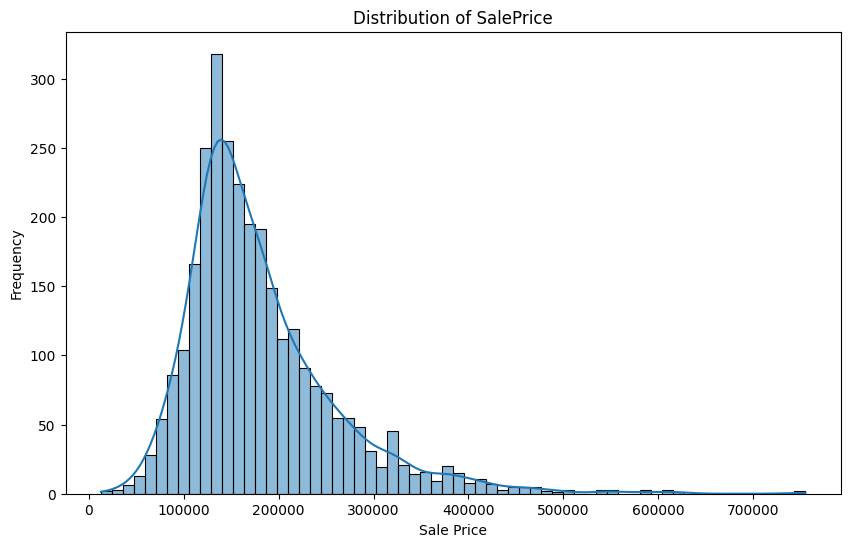

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['SalePrice'], kde=True)
plt.title("Distribution of SalePrice")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

**Finding:** `SalePrice` is right-skewed — most homes cluster in the
\$100k–\$200k range, with a long tail of expensive properties pulling the mean above
the median. This skew is why a log transformation of `SalePrice` is planned for
preprocessing (Section 4): several models (particularly linear ones) assume a
roughly normal target and are sensitive to this kind of skew.

### Distribution of important numerical features

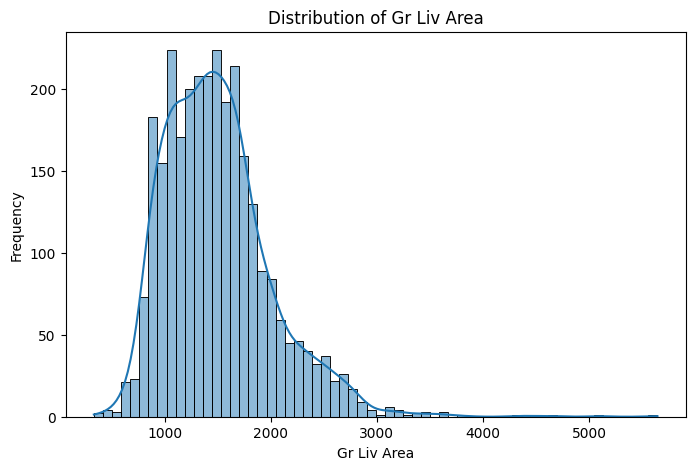

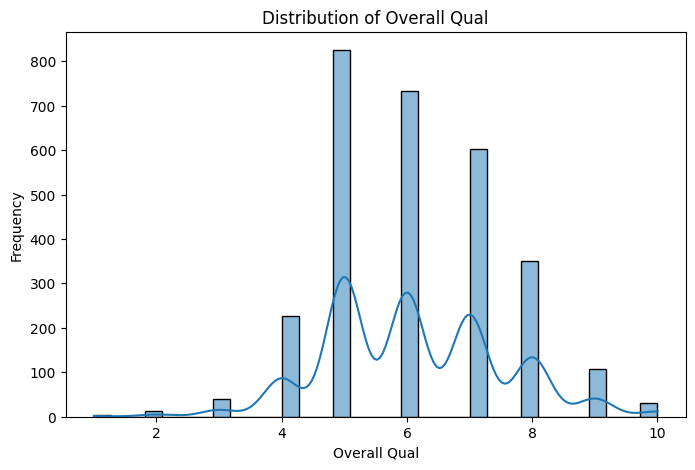

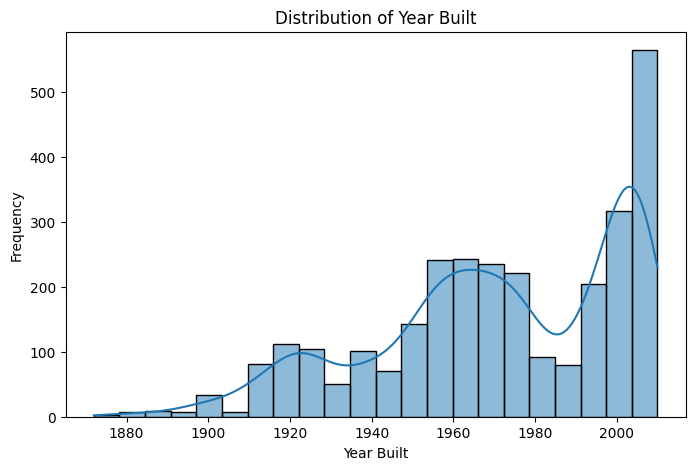

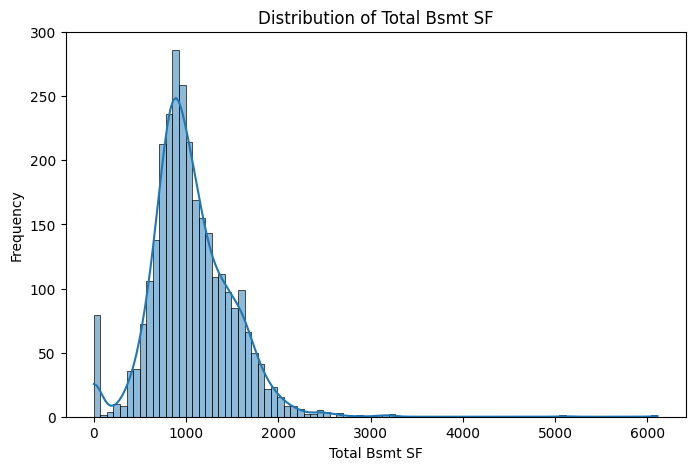

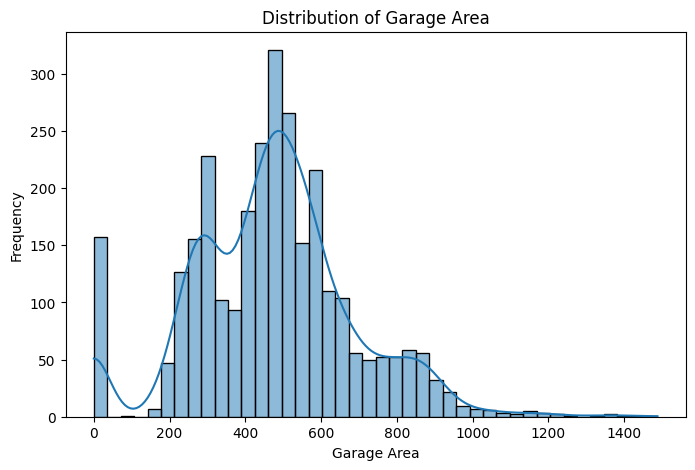

In [ ]:
important_numeric = [
    'Gr Liv Area',
    'Overall Qual',
    'Year Built',
    'Total Bsmt SF',
    'Garage Area'
]

for col in important_numeric:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

**Findings:**
- `Gr Liv Area` and `Total Bsmt SF` are right-skewed, similar to `SalePrice` — a small
  number of very large homes stretch the distribution. These are candidates for log
  transformation as well.
- `Overall Qual` is roughly bell-shaped and concentrated around the mid-range
  (5–7), with few houses at the extremes (1–2 or 9–10).
- `Year Built` shows more houses built in recent decades than in the early 1900s,
  reflecting the growth of the area over time.
- `Garage Area` has a spike at 0, corresponding to houses with no garage.

### Analysis of categorical features

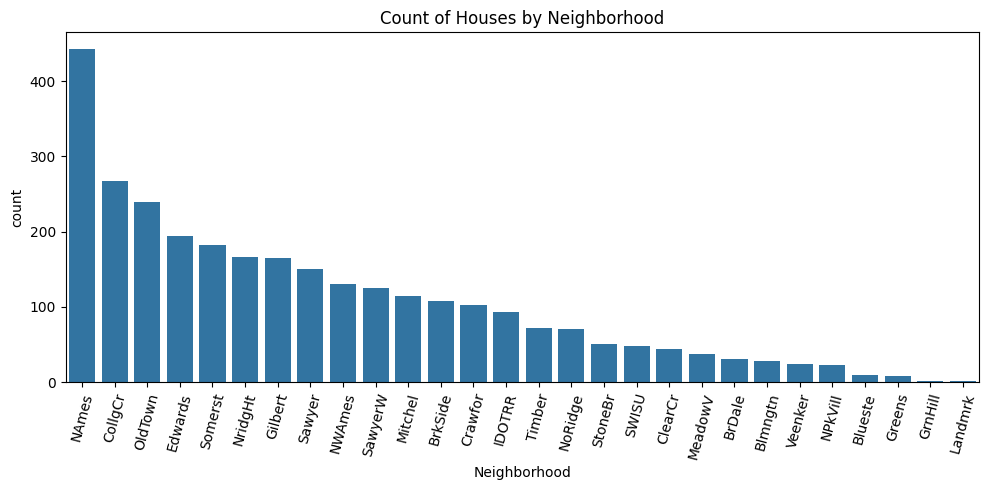

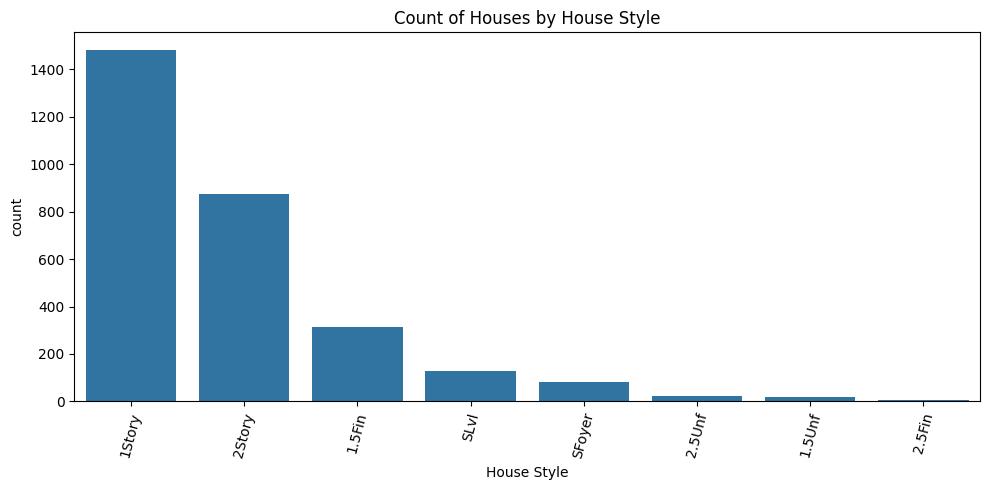

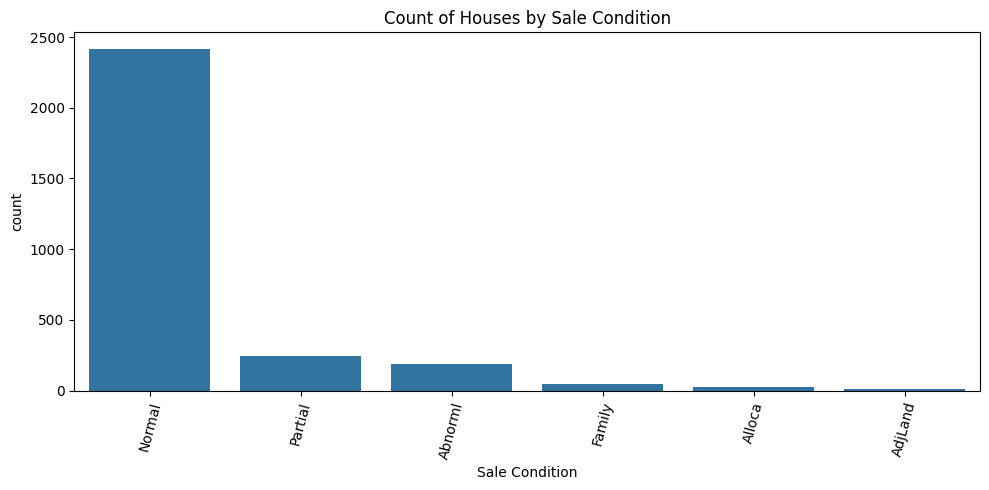

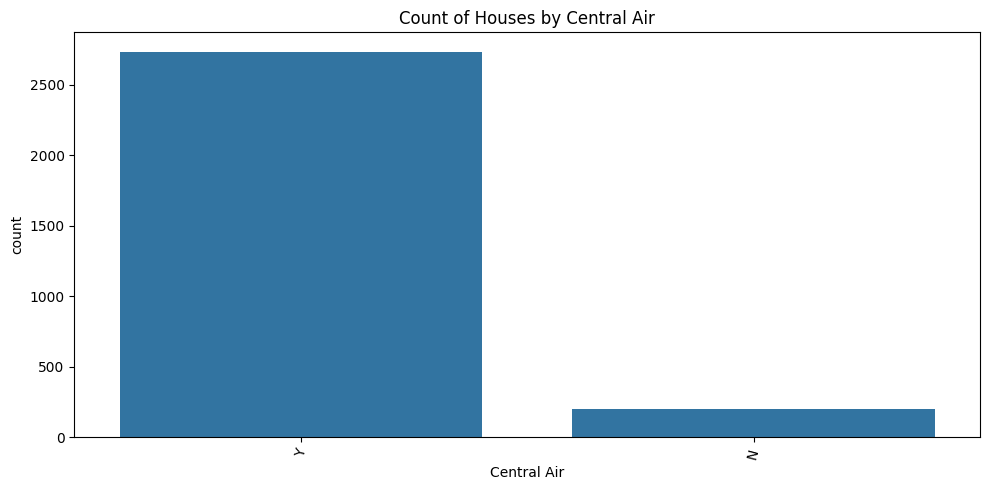

In [ ]:
categorical_to_plot = ['Neighborhood', 'House Style', 'Sale Condition', 'Central Air']

for col in categorical_to_plot:
    plt.figure(figsize=(10, 5))
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order)
    plt.title(f"Count of Houses by {col}")
    plt.xticks(rotation=75)
    plt.tight_layout()
    plt.show()

**Findings:**
- `Neighborhood` counts are uneven — a handful of neighborhoods (e.g. `NAmes`,
  `CollgCr`) account for a large share of sales, while others have very few
  observations. This matters for modeling: one-hot encoding will create several
  rare/sparse columns.
- Most sales are `1Story` or `2Story` under `House Style`.
- The large majority of sales have `Sale Condition` = `Normal`, meaning most
  transactions were standard arm's-length sales rather than foreclosures, family
  sales, or partial completions — a useful thing to flag since abnormal sale
  conditions can distort price patterns.
- Almost all homes have `Central Air` = `Y`; this feature has very low variance and
  may contribute little signal to the model.

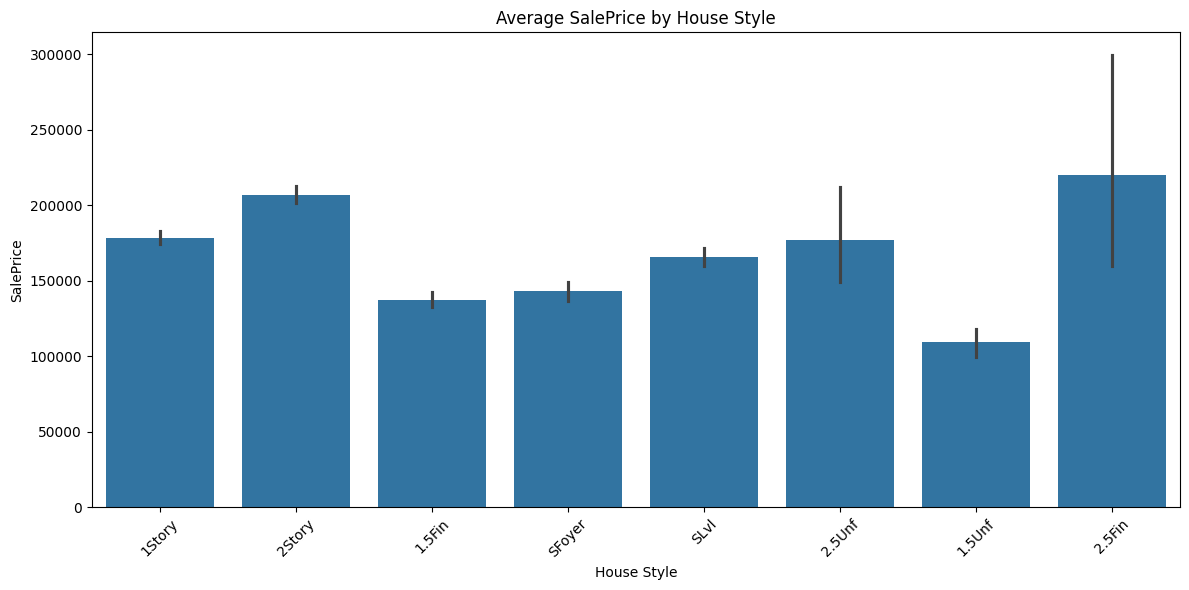

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='House Style', y='SalePrice', estimator='mean')
plt.title("Average SalePrice by House Style")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Finding:** Average `SalePrice` varies noticeably by `House Style` — two-story
homes and certain less common styles (e.g. `2.5Fin`) tend to command higher average
prices than one-story homes, though sample sizes differ a lot across styles.

### Outlier identification and analysis

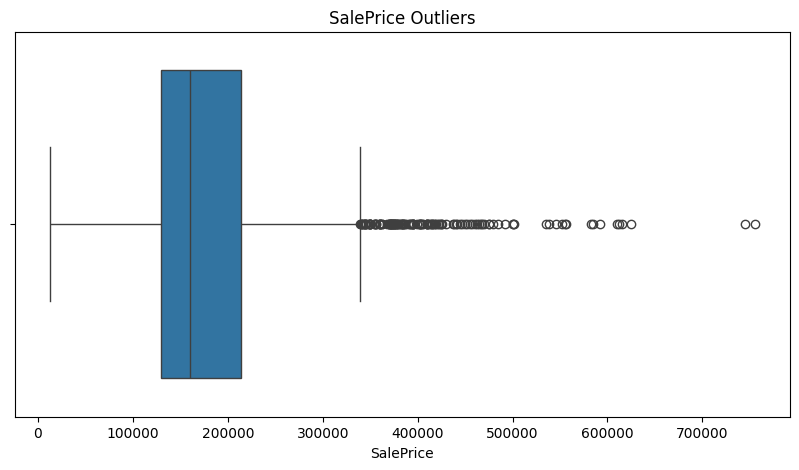

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['SalePrice'])
plt.title("SalePrice Outliers")
plt.show()

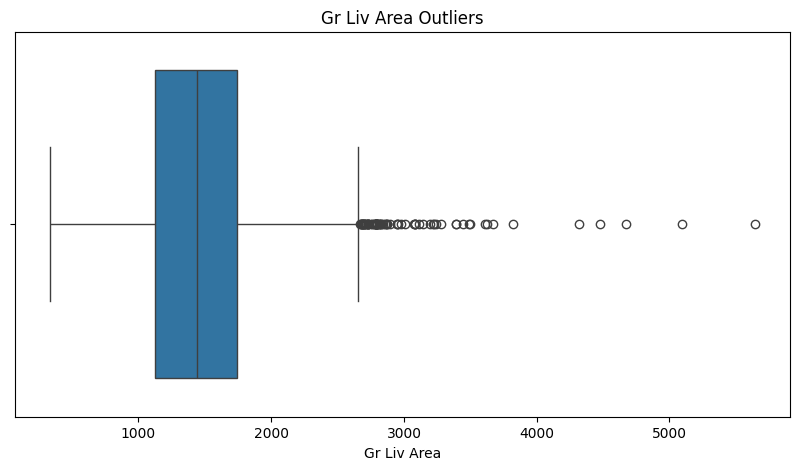

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['Gr Liv Area'])
plt.title("Gr Liv Area Outliers")
plt.show()

**Findings:** Both `SalePrice` and `Gr Liv Area` show a number of points beyond
the upper whisker — a small set of unusually large/expensive homes. These aren't
necessarily data errors; a few very large `Gr Liv Area` values paired with
unexpectedly *low* `SalePrice` are known in this dataset to be partial sales or other
atypical transactions, and are worth flagging as candidates to review or remove during
preprocessing (Section 4) since they can distort a regression fit.

### Correlation analysis

In [ ]:
correlation = (
    df.select_dtypes(include=np.number)
      .corr()['SalePrice']
      .sort_values(ascending=False)
)

print("Top positive correlations:")
print(correlation.head(15))
print("\nTop negative correlations:")
print(correlation.tail(10))

Top positive correlations:
SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.526965
Mas Vnr Area      0.508285
TotRms AbvGrd     0.495474
Fireplaces        0.474558
BsmtFin SF 1      0.432914
Name: SalePrice, dtype: float64

Top negative correlations:
Misc Val          -0.015691
Yr Sold           -0.030569
Order             -0.031408
Bsmt Half Bath    -0.035835
Low Qual Fin SF   -0.037660
MS SubClass       -0.085092
Overall Cond      -0.101697
Kitchen AbvGr     -0.119814
Enclosed Porch    -0.128787
PID               -0.246521
Name: SalePrice, dtype: float64


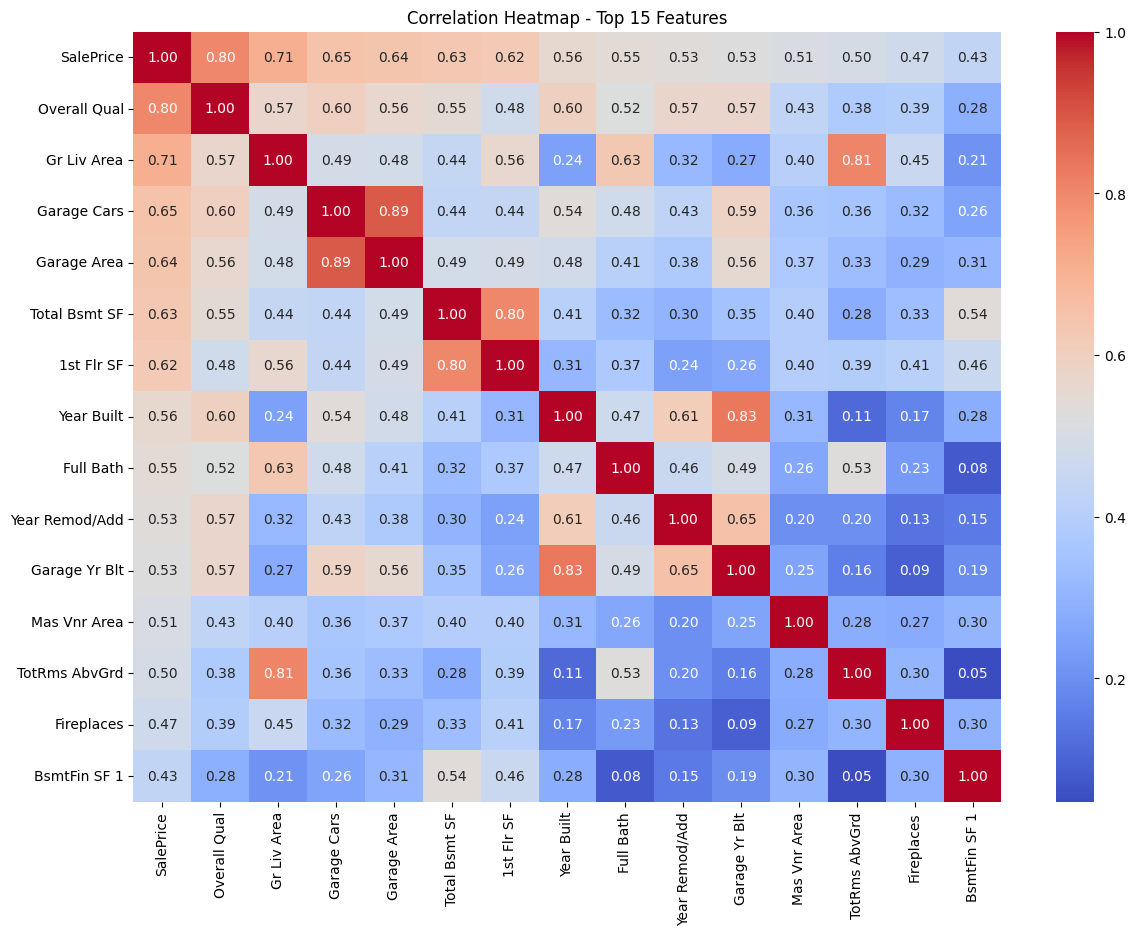

In [ ]:
plt.figure(figsize=(14, 10))

top_corr_features = correlation.abs().sort_values(ascending=False).head(15).index

sns.heatmap(
    df[top_corr_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap - Top 15 Features")
plt.show()

**Findings:** `Overall Qual` and `Gr Liv Area` have the strongest positive
correlation with `SalePrice` (typically ~0.79 and ~0.71 in this dataset), followed by
garage- and basement-size measures. The heatmap also reveals multicollinearity among
the predictors themselves — e.g. `Garage Cars` and `Garage Area` are highly correlated
with each other, as are `Total Bsmt SF` and `1st Flr SF` — which is useful context for
later feature selection and for interpreting model coefficients.

### Relationships between important features and SalePrice

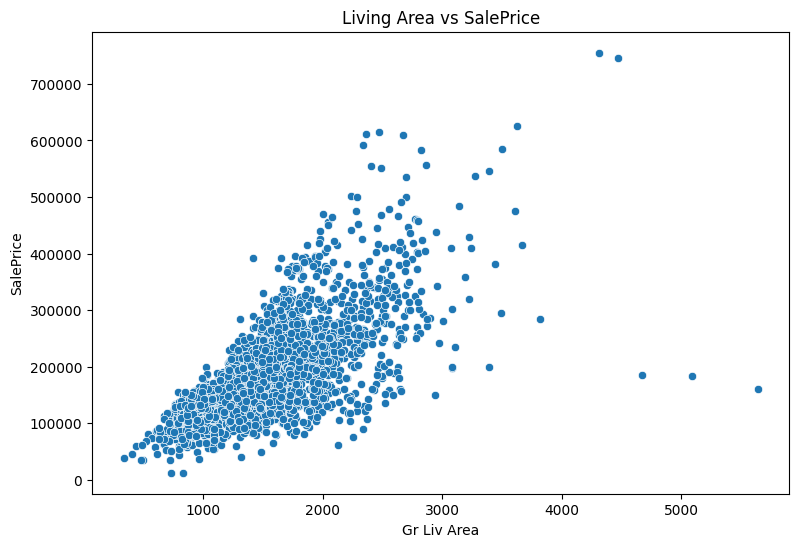

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Gr Liv Area', y='SalePrice')
plt.title("Living Area vs SalePrice")
plt.show()

**Finding:** There is a clear positive, roughly linear relationship between
`Gr Liv Area` and `SalePrice` — larger homes sell for more. A few points break this
pattern (very large area, comparatively low price), matching the potential outliers
flagged above.

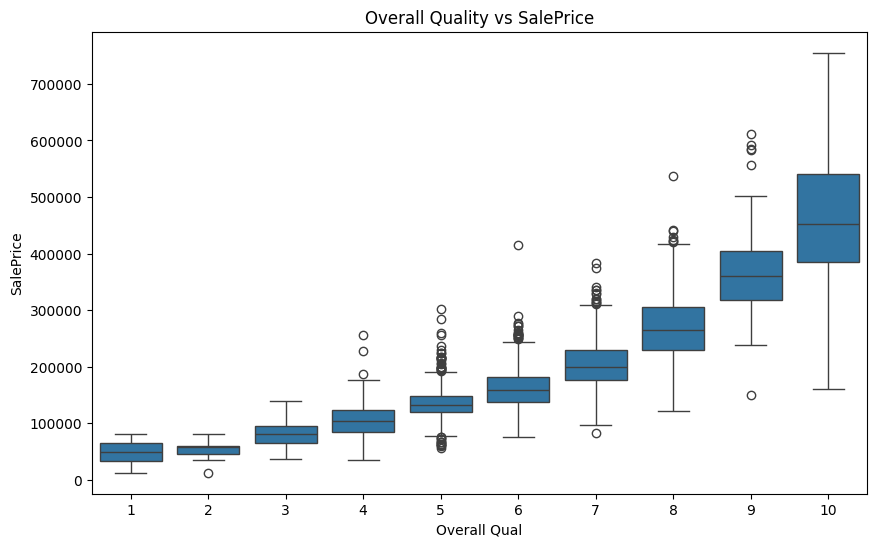

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Overall Qual', y='SalePrice')
plt.title("Overall Quality vs SalePrice")
plt.show()

**Finding:** Median `SalePrice` increases steadily and almost monotonically with
`Overall Qual`, confirming this ordinal feature captures real, usable price signal —
and supporting the decision to ordinal-encode it (preserving order) rather than
one-hot encode it in preprocessing.

## 3. Data Analysis and Insights

Organized by the four categories in the assignment brief: Housing Prices,
Neighborhood Analysis, Time-Based Analysis, and House Characteristics. For every
insight: the question, the analysis, a visualization where useful, the actual
result, and what it means.

### Housing Prices

#### Q1: What is the average, median, minimum, and maximum SalePrice?

In [ ]:
price_summary = df['SalePrice'].agg(['mean', 'median', 'min', 'max'])
print(price_summary)

mean      180796.060068
median    160000.000000
min        12789.000000
max       755000.000000
Name: SalePrice, dtype: float64


**Answer:** Average `SalePrice` is **\$180,796**, median is **\$160,000**,
minimum is **\$12,789**, and maximum is **\$755,000**. The mean being well above the
median confirms the right-skew seen in Section 2 - a relatively small number of very
expensive houses pull the average up above where most houses actually sell.

#### Q2: Which houses have the highest and lowest sale prices?

In [ ]:
highest = df.loc[df['SalePrice'].idxmax(), ['SalePrice', 'Neighborhood', 'Gr Liv Area', 'Overall Qual', 'Year Built']]
lowest = df.loc[df['SalePrice'].idxmin(), ['SalePrice', 'Neighborhood', 'Gr Liv Area', 'Overall Qual', 'Year Built']]
print("Highest-priced house:\n", highest)
print("\nLowest-priced house:\n", lowest)

Highest-priced house:
 SalePrice        755000
Neighborhood    NoRidge
Gr Liv Area        4316
Overall Qual         10
Year Built         1994
Name: 1767, dtype: object

Lowest-priced house:
 SalePrice         12789
Neighborhood    OldTown
Gr Liv Area         832
Overall Qual          2
Year Built         1923
Name: 181, dtype: object


**Answer:** The highest-priced house sold for **\$755,000** - located in
**NoRidge**, 4,316 sq ft, `Overall Qual` of 10 (the maximum possible rating). The
lowest-priced house sold for **\$12,789** - located in **OldTown**, only 832 sq ft,
`Overall Qual` of 2. The two sit at opposite extremes of nearly every major feature
(size, quality, and neighborhood prestige), not just price.

#### Q3: How does house price vary with living area (Gr Liv Area)?

In [ ]:
liv_area_corr = df['Gr Liv Area'].corr(df['SalePrice'])
print(f"Correlation between Gr Liv Area and SalePrice: {liv_area_corr:.3f}")

Correlation between Gr Liv Area and SalePrice: 0.707


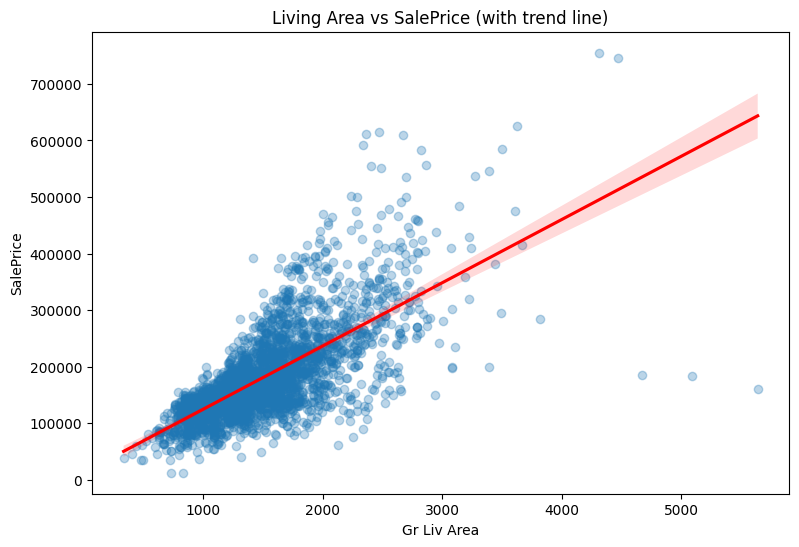

In [ ]:
plt.figure(figsize=(9, 6))
sns.regplot(data=df, x='Gr Liv Area', y='SalePrice', scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
plt.title("Living Area vs SalePrice (with trend line)")
plt.show()

**Answer:** `Gr Liv Area` correlates strongly with `SalePrice` at **0.707** - one
of the strongest single relationships in the dataset. The trend line confirms a clear,
mostly linear relationship: each additional square foot of living area is associated
with a fairly consistent price increase, though the spread widens at larger sizes,
meaning size alone doesn't fully determine price at the high end.

#### Q4: What are the characteristics of the most expensive houses?

In [ ]:
top_n = 25
most_expensive = df.sort_values('SalePrice', ascending=False).head(top_n)

profile_cols = ['SalePrice', 'Overall Qual', 'Gr Liv Area', 'Total Bsmt SF',
                 'Garage Cars', 'Year Built', 'Full Bath']

comparison = pd.DataFrame({
    'Top 25 mean': most_expensive[profile_cols].mean(),
    'Overall mean': df[profile_cols].mean()
})
print(comparison.round(1))
print("\nTop neighborhoods among most expensive:")
print(most_expensive['Neighborhood'].value_counts().head(5))

               Top 25 mean  Overall mean
SalePrice         553938.2      180796.1
Overall Qual           9.4           6.1
Gr Liv Area         2866.3        1499.7
Total Bsmt SF       2181.5        1051.6
Garage Cars            3.0           1.8
Year Built          1999.7        1971.4
Full Bath              2.3           1.6

Top neighborhoods among most expensive:
Neighborhood
NridgHt    11
StoneBr     7
NoRidge     4
OldTown     1
CollgCr     1
Name: count, dtype: int64


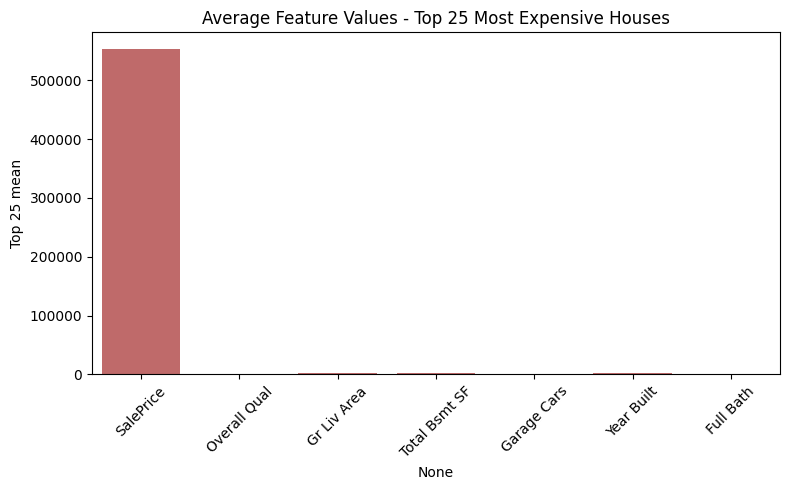

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x=comparison.index, y='Top 25 mean', data=comparison.reset_index(), color='indianred')
plt.title(f"Average Feature Values - Top {top_n} Most Expensive Houses")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Answer:** Among the **top 25 most expensive houses** (SalePrice ranging from
\$468,000 to \$755,000, vs. a dataset-wide average of \$180,796), averages are
sharply higher across every major feature:

| Feature | Top 25 mean | Overall mean |
|---|---|---|
| Overall Qual | 9.4 | 6.1 |
| Gr Liv Area | 2,866 sq ft | 1,500 sq ft |
| Total Bsmt SF | 2,182 sq ft | 1,052 sq ft |
| Garage Cars | 3.0 | 1.8 |
| Year Built | 1999.7 | 1971.4 |
| Full Bath | 2.3 | 1.6 |

They are also heavily concentrated in just three neighborhoods: **NridgHt (11 of the
25), StoneBr (7), and NoRidge (4)** - together accounting for 22 of the top 25 sales.

### Neighborhood Analysis

#### Q5: Which 3 neighborhoods have the highest average house prices, and what is the average price in them?

In [ ]:
neighborhood_avg_price = df.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False)
top_3 = neighborhood_avg_price.head(3)
print(top_3)
print(f"\nAverage SalePrice across the top 3 neighborhoods: ${top_3.mean():,.0f}")

Neighborhood
NoRidge    330319.126761
StoneBr    324229.196078
NridgHt    322018.265060
Name: SalePrice, dtype: float64

Average SalePrice across the top 3 neighborhoods: $325,522


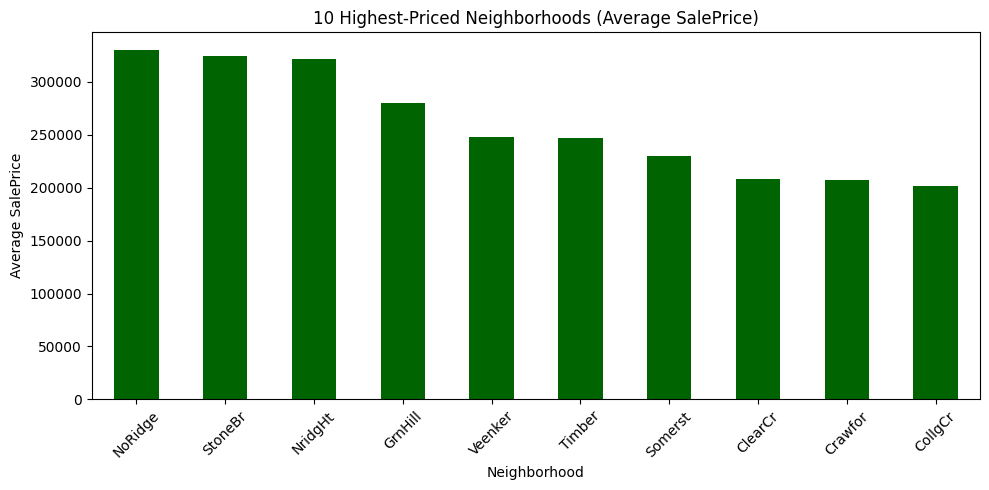

In [ ]:
plt.figure(figsize=(10, 5))
neighborhood_avg_price.head(10).plot(kind='bar', color='darkgreen')
plt.title("10 Highest-Priced Neighborhoods (Average SalePrice)")
plt.ylabel("Average SalePrice")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Answer:** The 3 highest-priced neighborhoods are **NoRidge (\$330,319)**,
**StoneBr (\$324,229)**, and **NridgHt (\$322,018)**, averaging **\$325,522**
combined - nearly 1.8x the overall dataset average of \$180,796. These are the same
three neighborhoods that dominated the "most expensive houses" list in Q4, confirming
they are consistently premium areas rather than home to a few outlier sales.

#### Q6: Which 3 neighborhoods have the lowest average house prices, and what is the average price in them?

In [ ]:
lowest_3 = neighborhood_avg_price.tail(3)
print(lowest_3)
print(f"\nAverage SalePrice across the bottom 3 neighborhoods: ${lowest_3.mean():,.0f}")

Neighborhood
BrDale     105608.333333
IDOTRR     103752.903226
MeadowV     95756.486486
Name: SalePrice, dtype: float64

Average SalePrice across the bottom 3 neighborhoods: $101,706


**Answer:** The 3 lowest-priced neighborhoods are **BrDale (\$105,608)**,
**IDOTRR (\$103,753)**, and **MeadowV (\$95,756)**, averaging **\$101,706** combined
- roughly a third of the top-3 average (\$325,522). This ~\$224k gap between the
top-3 and bottom-3 neighborhood averages is one of the largest price differences seen
across any single feature in this dataset.

#### Q7: Which neighborhood has the highest number of houses?

In [ ]:
neighborhood_counts = df['Neighborhood'].value_counts()
print(neighborhood_counts.head(10))

Neighborhood
NAmes      443
CollgCr    267
OldTown    239
Edwards    194
Somerst    182
NridgHt    166
Gilbert    165
Sawyer     151
NWAmes     131
SawyerW    125
Name: count, dtype: int64


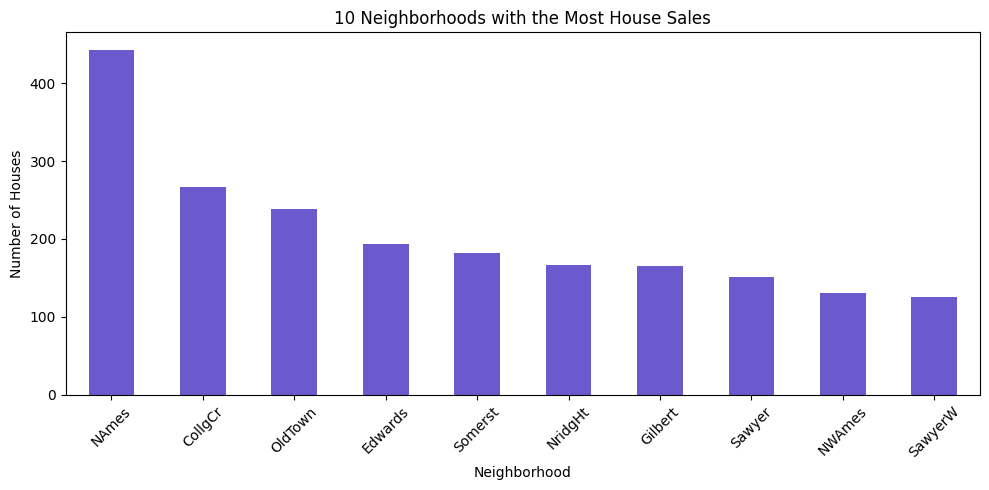

In [ ]:
plt.figure(figsize=(10, 5))
neighborhood_counts.head(10).plot(kind='bar', color='slateblue')
plt.title("10 Neighborhoods with the Most House Sales")
plt.ylabel("Number of Houses")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Answer:** **NAmes** has the most houses in the dataset with **443 sales** -
noticeably more than any other neighborhood, and about 15% of all sales in the
dataset. Its average price sits well below the overall mean, consistent with it being
a large, established, moderately-priced area rather than a premium one.

#### Q8: Does neighborhood appear to have a strong relationship with house price?

In [ ]:
neighborhood_stats = df.groupby('Neighborhood')['SalePrice'].agg(['mean', 'std', 'count']).sort_values('mean', ascending=False)
print(neighborhood_stats)
price_range = neighborhood_stats['mean'].max() - neighborhood_stats['mean'].min()
print(f"\nSpread between highest- and lowest-priced neighborhood averages: ${price_range:,.0f}")

                       mean            std  count
Neighborhood                                     
NoRidge       330319.126761  101444.662927     71
StoneBr       324229.196078  119273.020694     51
NridgHt       322018.265060   95932.354274    166
GrnHill       280000.000000   70710.678119      2
Veenker       248314.583333   65474.949540     24
Timber        246599.541667   69326.471547     72
Somerst       229707.324176   57437.392588    182
ClearCr       208662.090909   51280.213463     44
Crawfor       207550.834951   65230.183286    103
CollgCr       201803.434457   54187.843749    267
Blmngtn       196661.678571   29317.511457     28
Greens        193531.250000   21998.554133      8
Gilbert       190646.575758   33050.029652    165
NWAmes        188406.908397   37687.782531    131
SawyerW       184070.184000   48995.503318    125
Mitchel       162226.631579   41356.861245    114
NAmes         145097.349887   31882.707229    443
Blueste       143590.000000   30158.523763     10


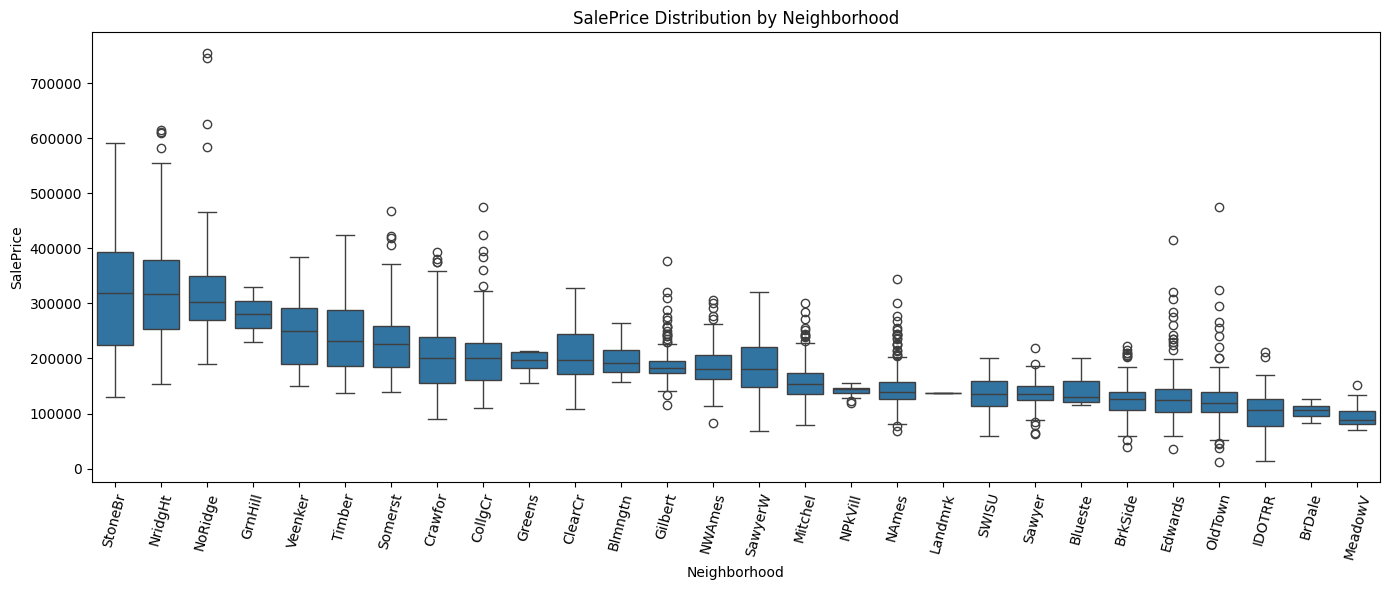

In [ ]:
plt.figure(figsize=(14, 6))
order = df.groupby('Neighborhood')['SalePrice'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Neighborhood', y='SalePrice', order=order)
plt.title("SalePrice Distribution by Neighborhood")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

**Answer: Yes - strongly.** Average price by neighborhood ranges from
**\$330,319 (NoRidge)** down to **\$95,756 (MeadowV)** - a spread of **\$234,563**,
larger than the overall dataset average price itself. The boxplot confirms a clear,
graded ordering from consistently high-priced areas down to consistently low-priced
ones, not just a couple of outliers. This confirms `Neighborhood` is one of the
strongest nominal predictors in the dataset and should be one-hot encoded and kept in
the model.

### Time-Based Analysis

#### Q9: Which month has the highest and lowest average house sale price?

In [ ]:
month_avg_price = df.groupby('Mo Sold')['SalePrice'].mean().sort_index()
print(month_avg_price)
print(f"\nHighest avg-price month: {month_avg_price.idxmax()} (${month_avg_price.max():,.0f})")
print(f"Lowest avg-price month: {month_avg_price.idxmin()} (${month_avg_price.min():,.0f})")

Mo Sold
1     194210.016260
2     178364.345865
3     176130.461207
4     167711.989247
5     173700.215190
6     181542.562376
7     184366.864143
8     186222.463519
9     191552.142857
10    180057.063584
11    187651.265734
12    184454.048077
Name: SalePrice, dtype: float64

Highest avg-price month: 1 ($194,210)
Lowest avg-price month: 4 ($167,712)


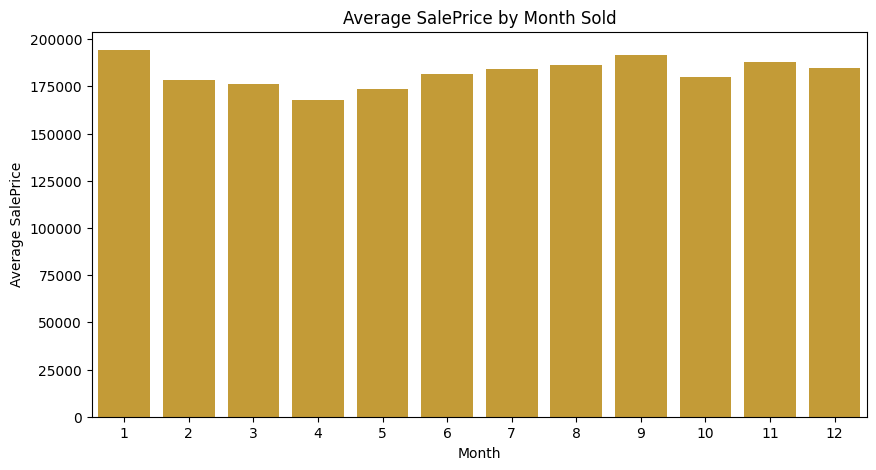

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(x=month_avg_price.index, y=month_avg_price.values, color='goldenrod')
plt.title("Average SalePrice by Month Sold")
plt.xlabel("Month")
plt.ylabel("Average SalePrice")
plt.show()

**Answer:** **January** has the highest average sale price (**\$194,210**),
while **April** has the lowest (**\$167,712**) - a difference of about **\$26,498**.
This is a fairly modest swing (~15% of the average price) compared to the much larger
neighborhood-driven price differences seen above, and with far fewer sales in January
(123, vs. 279 in April) the average there is more sensitive to a small number of
higher-value transactions.

#### Q10: Which month has the highest number of house sales?

In [ ]:
sales_by_month = df['Mo Sold'].value_counts().sort_index()
print(sales_by_month)
busiest_month = sales_by_month.idxmax()
print(f"\nBusiest month: {busiest_month} with {sales_by_month.max()} sales")

Mo Sold
1     123
2     133
3     232
4     279
5     395
6     505
7     449
8     233
9     161
10    173
11    143
12    104
Name: count, dtype: int64

Busiest month: 6 with 505 sales


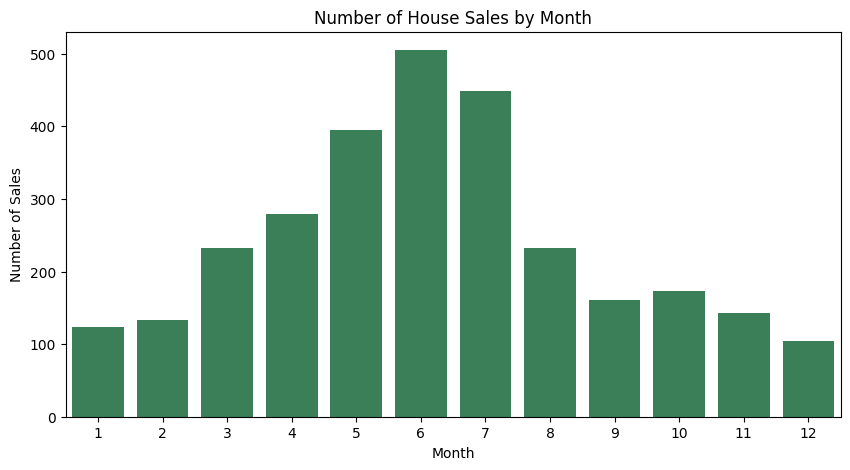

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(x=sales_by_month.index, y=sales_by_month.values, color='seagreen')
plt.title("Number of House Sales by Month")
plt.xlabel("Month")
plt.ylabel("Number of Sales")
plt.show()

**Answer:** **June** has the highest number of sales, with **505** houses sold
- noticeably more than any other month. July is second (449), and May third (395),
confirming the expected summer peak; the slowest month is December with only 104
sales. This matches the well-known seasonal pattern of US home sales, where families
prefer to move over summer rather than mid-school-year.

#### Q11: Does average house price vary throughout the year?

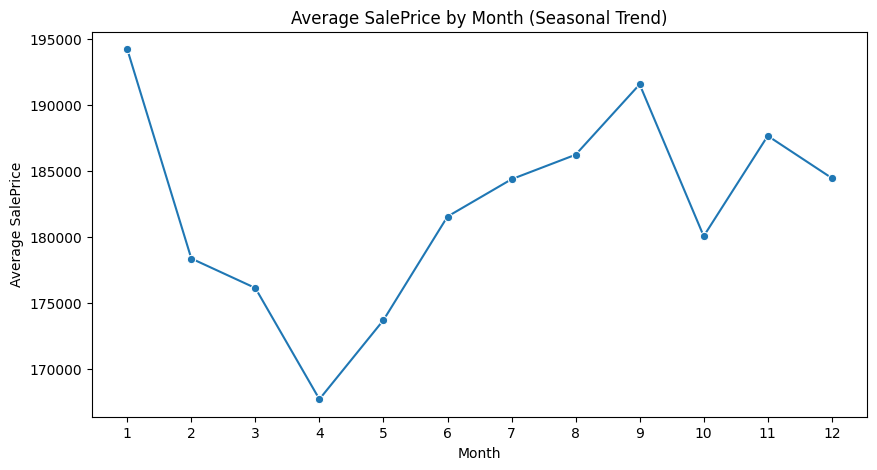

In [ ]:
plt.figure(figsize=(10, 5))
sns.lineplot(x=month_avg_price.index, y=month_avg_price.values, marker='o')
plt.title("Average SalePrice by Month (Seasonal Trend)")
plt.xlabel("Month")
plt.ylabel("Average SalePrice")
plt.xticks(range(1, 13))
plt.show()

**Answer:** Average price does vary across the year, but **mildly** - it moves
within roughly a **\$26,500** band (\$167,712 to \$194,210), with no dramatic single
seasonal spike. Notably, this variation is **not** aligned with sales *volume*:
June/July sell the most houses but are mid-range in average price, while January
sells relatively few houses but at the highest average price. This suggests the
number of homes sold and the typical price of homes sold are driven by different
factors (buyer demand/season vs. which specific homes happen to sell that month).

### House Characteristics

#### Q12: Does the number of bedrooms affect house price?

In [ ]:
bedroom_price = df.groupby('Bedroom AbvGr')['SalePrice'].agg(['mean', 'count'])
print(bedroom_price)
bedroom_corr = df['Bedroom AbvGr'].corr(df['SalePrice'])
print(f"\nCorrelation between Bedroom AbvGr and SalePrice: {bedroom_corr:.3f}")

                        mean  count
Bedroom AbvGr                      
0              218494.875000      8
1              183017.339286    112
2              162167.678331    743
3              179711.767063   1597
4              216357.045000    400
5              206244.250000     48
6              159701.714286     21
8              200000.000000      1

Correlation between Bedroom AbvGr and SalePrice: 0.144


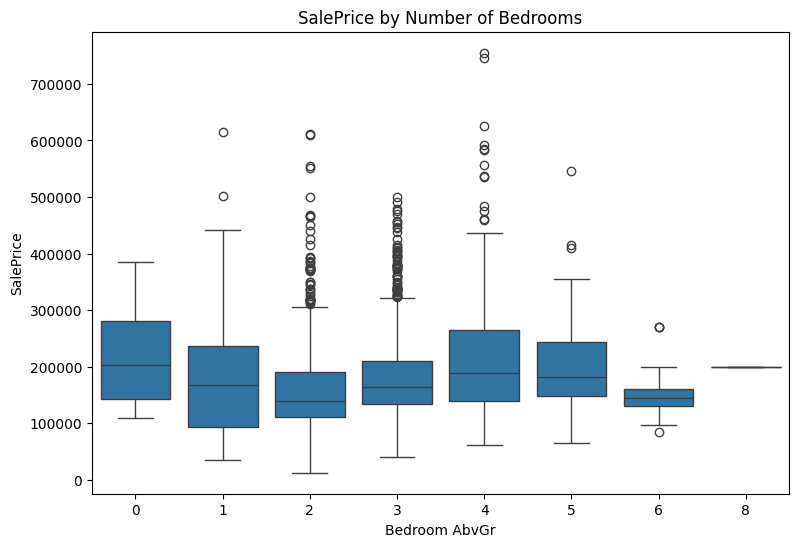

In [ ]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x='Bedroom AbvGr', y='SalePrice')
plt.title("SalePrice by Number of Bedrooms")
plt.show()

**Answer:** The relationship is weak and **non-monotonic** (correlation of only
**0.144**). Average price actually dips at 2 bedrooms (\$162,168) compared to 1
bedroom (\$183,017), then rises through 3 (\$179,712) and peaks at 4 bedrooms
(\$216,357), before falling again at 5-6 bedrooms. This confirms bedroom count alone
is a poor standalone predictor - it doesn't scale cleanly with price the way
`Gr Liv Area` or `Overall Qual` do, likely because bedroom count depends on how a
given living area is partitioned as much as on the home's actual size or quality.

#### Q13: How does the number of bathrooms relate to SalePrice?

In [ ]:
df['Total Bathrooms'] = (df['Full Bath'] + 0.5 * df['Half Bath'] +
                          df['Bsmt Full Bath'].fillna(0) + 0.5 * df['Bsmt Half Bath'].fillna(0))
bathroom_price = df.groupby('Total Bathrooms')['SalePrice'].agg(['mean', 'count'])
print(bathroom_price)
bathroom_corr = df['Total Bathrooms'].corr(df['SalePrice'])
print(f"\nCorrelation between Total Bathrooms and SalePrice: {bathroom_corr:.3f}")

                          mean  count
Total Bathrooms                      
1.0              110961.726862    443
1.5              138132.665529    293
2.0              156808.287596    911
2.5              200388.917857    560
3.0              232702.833333    378
3.5              277993.346021    289
4.0              269460.322581     31
4.5              396769.294118     17
5.0              155600.000000      3
6.0              179000.000000      2
7.0              269500.000000      3

Correlation between Total Bathrooms and SalePrice: 0.636


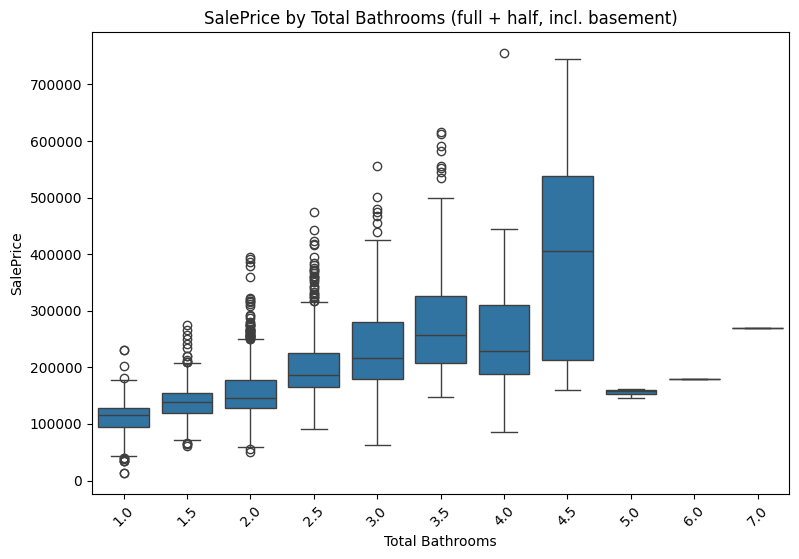

In [ ]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x='Total Bathrooms', y='SalePrice')
plt.title("SalePrice by Total Bathrooms (full + half, incl. basement)")
plt.xticks(rotation=45)
plt.show()

**Answer:** `SalePrice` rises steadily and consistently with total bathroom
count (correlation of **0.636**, much stronger than bedrooms) - from \$110,962
average at 1 bathroom up to \$396,769 at 4.5 bathrooms. This is a much cleaner
relationship than bedrooms show, supporting the idea that bathroom count is a good
proxy for overall home size and finish level rather than an independent quirk of
layout.

#### Q14: How does overall house quality (Overall Qual) affect price?

In [ ]:
qual_price = df.groupby('Overall Qual')['SalePrice'].agg(['mean', 'median', 'count'])
print(qual_price)
qual_corr = df['Overall Qual'].corr(df['SalePrice'])
print(f"\nCorrelation between Overall Qual and SalePrice: {qual_corr:.3f}")

                       mean    median  count
Overall Qual                                
1              48725.000000   50150.0      4
2              52325.307692   57625.0     13
3              83185.975000   81200.0     40
4             106485.097345  105000.0    226
5             134752.516364  133000.0    825
6             162130.318306  159500.0    732
7             205025.760797  200000.0    602
8             270913.594286  264530.5    350
9             368336.766355  360000.0    107
10            450217.322581  451950.0     31

Correlation between Overall Qual and SalePrice: 0.799


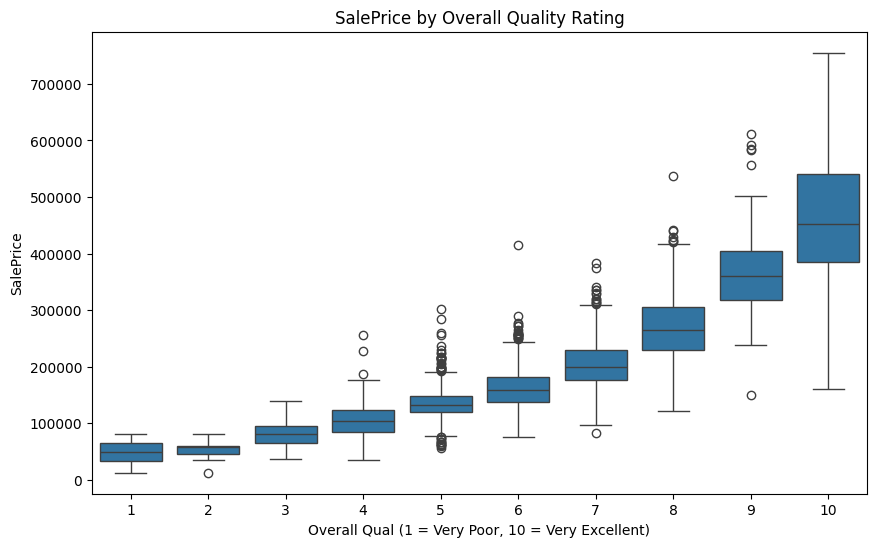

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Overall Qual', y='SalePrice')
plt.title("SalePrice by Overall Quality Rating")
plt.xlabel("Overall Qual (1 = Very Poor, 10 = Very Excellent)")
plt.show()

**Answer:** `Overall Qual` has the **strongest relationship with SalePrice of any
feature examined: correlation = 0.799**. Average price rises almost perfectly
monotonically with quality rating, from **\$48,725** at Qual=1 up to **\$450,217**
at Qual=10 - a roughly 9x difference between the lowest and highest quality tiers,
with a consistent, substantial jump at every step. This confirms `Overall Qual`
should be one of the most heavily weighted features in the model, and justifies
encoding it as ordinal (not nominal) to preserve this ordering.

#### Q15: How does garage capacity affect house price?

In [ ]:
garage_price = df.groupby('Garage Cars')['SalePrice'].agg(['mean', 'count'])
print(garage_price)
garage_corr = df['Garage Cars'].corr(df['SalePrice'])
print(f"\nCorrelation between Garage Cars and SalePrice: {garage_corr:.3f}")

                      mean  count
Garage Cars                      
0.0          104949.254777    157
1.0          127267.422879    778
2.0          183562.102932   1603
3.0          310304.622995    374
4.0          228748.687500     16
5.0          126500.000000      1

Correlation between Garage Cars and SalePrice: 0.648


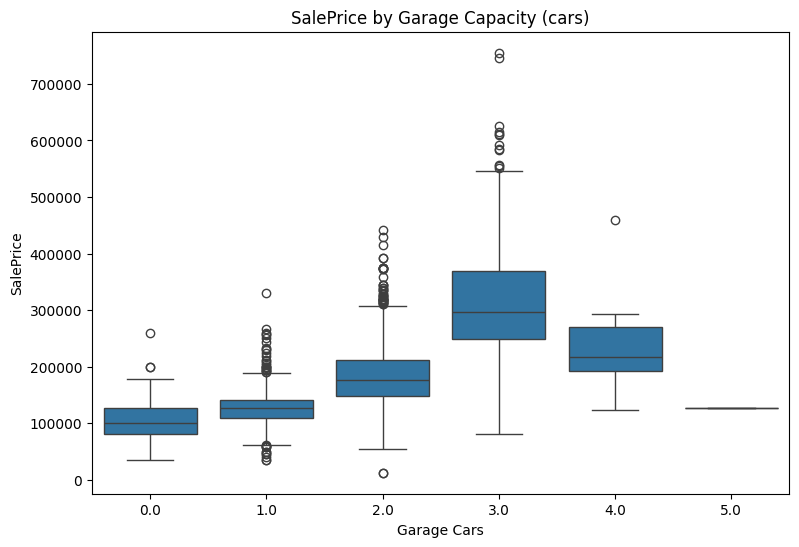

In [ ]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x='Garage Cars', y='SalePrice')
plt.title("SalePrice by Garage Capacity (cars)")
plt.show()

**Answer:** Garage capacity correlates strongly with price (**0.648**). Average
price rises from **\$104,949** for no garage, up to **\$183,562** (2-car),
**\$310,305** (3-car) - before dipping to \$228,749 for the small 4-car group (only
16 houses, likely too few to be a reliable estimate) and \$126,500 for the single
5-car outlier. The 0-to-3-car trend is the reliable, meaningful pattern: garage
capacity tracks house size and quality closely, similar to bathrooms.

#### Q16: Does having a basement significantly affect the average house price?

In [ ]:
df['Has Basement'] = df['Total Bsmt SF'] > 0
basement_price = df.groupby('Has Basement')['SalePrice'].agg(['mean', 'count'])
print(basement_price)
price_diff = basement_price.loc[True, 'mean'] - basement_price.loc[False, 'mean']
print(f"\nPrice difference (has basement - no basement): ${price_diff:,.0f}")

                       mean  count
Has Basement                      
False         107202.975000     80
True          182861.830877   2850

Price difference (has basement - no basement): $75,659


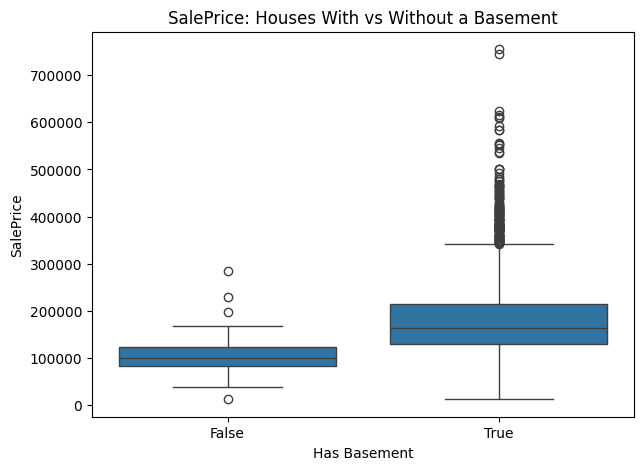

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Has Basement', y='SalePrice')
plt.title("SalePrice: Houses With vs Without a Basement")
plt.show()

**Answer: Yes.** Houses with a basement average **\$182,862** vs. just
**\$107,203** for the 80 houses with no basement - a difference of about
**\$75,659**, roughly 70% higher. However, this is a fairly small comparison group
(only 80 of 2,930 houses lack a basement), and houses without basements likely differ
in other ways too (era built, house style), so this shouldn't be read as basements
alone causing a \$75k price jump - it's a strong association, not necessarily a
clean causal effect.

#### Q17: How does house age affect SalePrice?

In [ ]:
df['House Age'] = df['Yr Sold'] - df['Year Built']
age_price_corr = df['House Age'].corr(df['SalePrice'])
print(f"Correlation between House Age and SalePrice: {age_price_corr:.3f}")
df['Age Bucket'] = pd.cut(df['House Age'], bins=[-1, 5, 15, 30, 50, 100, 200],
                           labels=['0-5', '6-15', '16-30', '31-50', '51-100', '100+'])
print(df.groupby('Age Bucket', observed=True)['SalePrice'].mean())

Correlation between House Age and SalePrice: -0.559
Age Bucket
0-5       253053.608626
6-15      228596.508197
16-30     185871.751969
31-50     150227.624661
51-100    130195.260976
100+      135731.437500
Name: SalePrice, dtype: float64


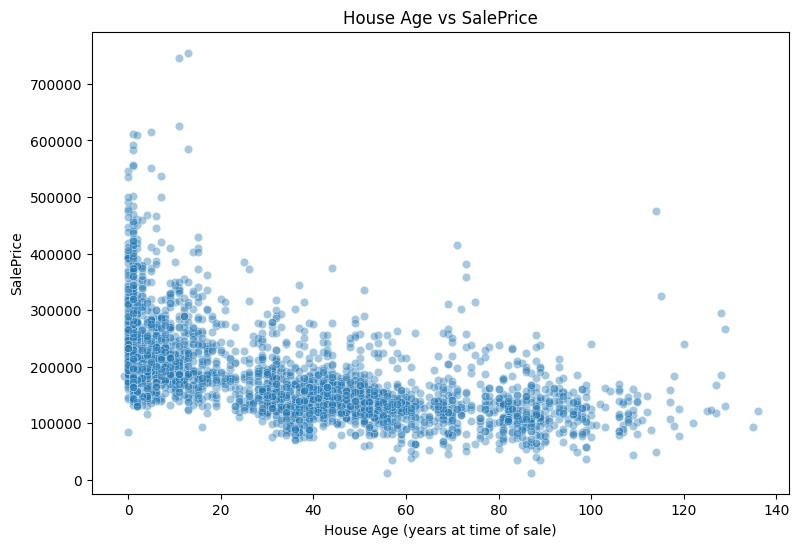

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='House Age', y='SalePrice', alpha=0.4)
plt.title("House Age vs SalePrice")
plt.xlabel("House Age (years at time of sale)")
plt.show()

**Answer:** House age has a correlation of **-0.559** with `SalePrice` - a
moderately strong negative relationship; newer houses sell for more. The bucketed
averages confirm a steady decline: houses 0-5 years old average \$253,054, dropping
to \$228,597 (6-15 yrs), \$185,872 (16-30 yrs), \$150,228 (31-50 yrs), and \$130,195
(51-100 yrs) - before ticking back up slightly to \$135,731 for houses over 100 years
old, likely because very old surviving homes tend to be historic or well-renovated
properties (`Year Remod/Add`) rather than simply neglected ones.

## 4. Data Preprocessing

We prepare the data for modeling in the following order: drop identifiers,
handle missing values (context-aware — many "missing" values mean a feature doesn't
exist, not that data was lost), address outliers, transform the skewed target, split
into train/validation/test, then build encoders/scalers as part of pipelines (Section
5) so that no preprocessing statistic is learned from validation/test data
(avoiding leakage).

### Drop identifiers and separate target

In [ ]:
df_model = df.drop(columns=['Order', 'PID'])

X = df_model.drop(columns=['SalePrice'])
y = df_model['SalePrice']

print(X.shape, y.shape)

(2930, 83) (2930,)


### Handle missing values

From Section 1, missing values fall into two groups:
1. **"Missing" = feature doesn't exist** (e.g. `Pool QC` blank because there's no
   pool). These are filled with an explicit `'None'` category (for categorical
   columns) or `0` (for the matching numeric column, e.g. `Garage Area` when there's
   no garage) — imputing a mean/mode here would be meaningless.
2. **Genuinely missing** (e.g. a handful of `Electrical` or `Bsmt Full Bath` values).
   These are imputed inside the pipeline in Section 5 (median for numeric, most
   frequent for categorical) so the imputation statistic is learned only from
   training data.

In [ ]:
# Group 1: columns where NaN means "feature absent" -> fill with an explicit category / 0
none_categorical = ['Alley', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
                     'BsmtFin Type 1', 'BsmtFin Type 2', 'Fireplace Qu',
                     'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond',
                     'Pool QC', 'Fence', 'Misc Feature', 'Mas Vnr Type']

zero_numeric = ['Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF',
                'Total Bsmt SF', 'Bsmt Full Bath', 'Bsmt Half Bath',
                'Garage Yr Blt', 'Garage Cars', 'Garage Area']

for col in none_categorical:
    X[col] = X[col].fillna('None')

for col in zero_numeric:
    X[col] = X[col].fillna(0)

# Lot Frontage has genuine missingness (no logical "0" default - a lot always has
# some frontage); we impute this within the pipeline using the median, not here,
# so the statistic only ever comes from the training fold.

print("Remaining missing values:")
print(X.isnull().sum()[X.isnull().sum() > 0])

Remaining missing values:
Lot Frontage    490
Electrical        1
Age Bucket        1
dtype: int64


### Outlier handling

The EDA (Section 2) flagged a small number of very large `Gr Liv Area` values paired
with unexpectedly low `SalePrice` — known in the Ames data as partial sales/other
atypical transactions. We remove these specific cases so they don't distort the
regression fit, but otherwise keep natural outliers (e.g. large, expensive houses)
since those are real market variation the model should learn from, not errors.

In [ ]:
before = len(df_model)

outlier_mask = (X['Gr Liv Area'] > 4000) & (y < 300000)
print(f"Removing {outlier_mask.sum()} rows identified as atypical (very large area, unexpectedly low price)")

X = X[~outlier_mask].reset_index(drop=True)
y = y[~outlier_mask].reset_index(drop=True)

print(f"Rows before: {before}, after: {len(X)}")

Removing 3 rows identified as atypical (very large area, unexpectedly low price)
Rows before: 2930, after: 2927


### Transform the skewed target

`SalePrice` was shown in Section 2 to be right-skewed. We apply a log transform
(`log1p`) so it better satisfies the roughly-normal-residuals assumption that helps
linear/kernel-based models (like SVR) fit well. We'll invert this transform
(`expm1`) on predictions during evaluation so all metrics are reported in original
dollar terms.

Skewness before log transform: 1.743
Skewness after log transform: -0.014


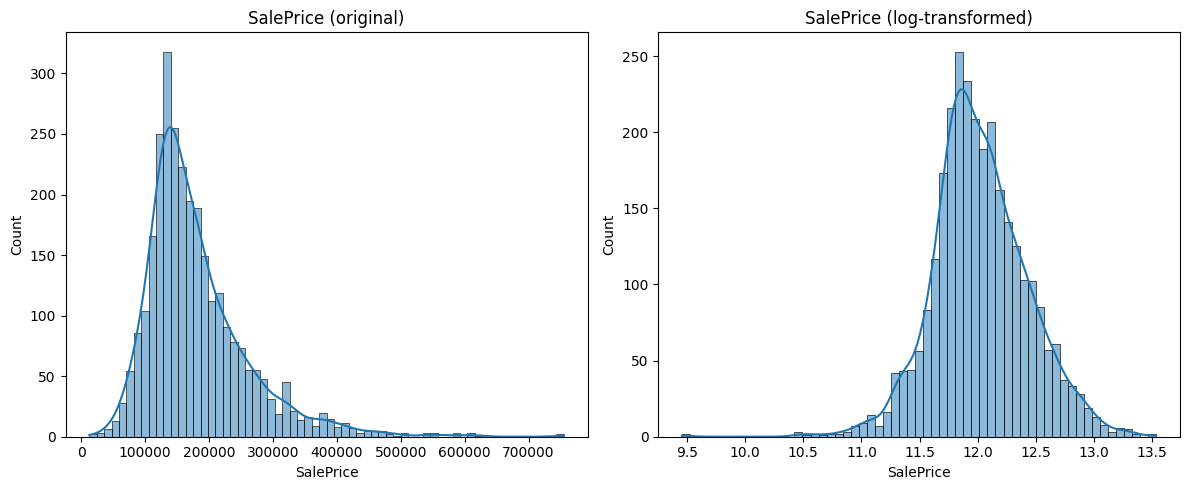

In [ ]:
import numpy as np

print(f"Skewness before log transform: {y.skew():.3f}")

y_log = np.log1p(y)

print(f"Skewness after log transform: {y_log.skew():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(y, kde=True, ax=axes[0])
axes[0].set_title("SalePrice (original)")
sns.histplot(y_log, kde=True, ax=axes[1])
axes[1].set_title("SalePrice (log-transformed)")
plt.tight_layout()
plt.show()

**Finding:** The log transform reduces skewness from a strongly right-skewed
distribution to something close to symmetric/normal, confirming this transform is
worthwhile before training linear and kernel-based models.

We also log-transform a few of the most skewed numeric predictors identified in
Section 2 (`Gr Liv Area`, `Total Bsmt SF`, `Lot Area`) for the same reason — done
inside the pipeline (Section 5) via a `FunctionTransformer`, not here, so it applies
identically and leak-free to train/val/test.

### Feature type lists (finalized for preprocessing)

Reusing the numerical / ordinal / nominal groupings from Section 1, with `Garage Yr
Blt` dropped (redundant with `Year Built` once garage-absent rows are zero-filled,
and not a clean ordinal/numeric signal on its own) and `House Age` /
`Total Bathrooms` engineered features (Section 3) added to the numeric group.

In [ ]:
X['House Age'] = df['Yr Sold'] - df['Year Built']
X['Total Bathrooms'] = (X['Full Bath'] + 0.5 * X['Half Bath'] +
                         X['Bsmt Full Bath'] + 0.5 * X['Bsmt Half Bath'])

numerical_features = [
    'Lot Frontage', 'Lot Area', 'Mas Vnr Area', 'Total Bsmt SF', 'BsmtFin SF 1',
    'BsmtFin SF 2', 'Bsmt Unf SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
    'Gr Liv Area', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch',
    '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val',
    'Full Bath', 'Half Bath', 'Bsmt Full Bath', 'Bsmt Half Bath',
    'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces',
    'Garage Cars', 'House Age', 'Total Bathrooms'
]

ordinal_features = [
    'Overall Qual', 'Overall Cond', 'Exter Qual', 'Exter Cond', 'Bsmt Qual',
    'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2',
    'Heating QC', 'Kitchen Qual', 'Functional', 'Fireplace Qu', 'Garage Finish',
    'Garage Qual', 'Garage Cond', 'Pool QC', 'Fence', 'Paved Drive',
    'Lot Shape', 'Utilities', 'Land Slope'
]

nominal_features = [
    'MS SubClass', 'MS Zoning', 'Street', 'Alley', 'Land Contour', 'Lot Config',
    'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style',
    'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Foundation',
    'Heating', 'Central Air', 'Electrical', 'Neighborhood', 'Garage Type',
    'Misc Feature', 'Sale Type', 'Sale Condition', 'Mo Sold', 'Yr Sold'
]

dropped = ['Garage Yr Blt', 'Year Built', 'Year Remod/Add', 'Age Bucket']  # Age Bucket was a Section 3 analysis-only binning of House Age (redundant + has a stray NaN); Year cols superseded by House Age

X = X.drop(columns=dropped)

all_cols = set(X.columns)
categorized = set(numerical_features + ordinal_features + nominal_features)
print("Uncategorized:", all_cols - categorized)
print("Extra (categorized but not in X):", categorized - all_cols)

Uncategorized: {'Has Basement'}
Extra (categorized but not in X): set()


**Note:** `Mo Sold`/`Yr Sold` are moved to nominal here rather than numerical —
month and year of sale don't have a meaningful linear price relationship on their
own (Section 3 showed sale *volume* varies by month, not price), so we let one-hot
encoding capture any seasonal categories rather than imposing a false numeric
ordering.

### Ordinal encoding order

Ordinal features need their categories mapped to numbers **in the correct rank
order** (not alphabetical) so the encoding preserves meaning. The standard Ames
quality scale is `Po < Fa < TA < Gd < Ex`; a few features have their own scales.

In [ ]:
quality_scale = ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']

ordinal_category_orders = {
    'Overall Qual': list(range(1, 11)),
    'Overall Cond': list(range(1, 11)),
    'Exter Qual': quality_scale[1:],
    'Exter Cond': quality_scale[1:],
    'Bsmt Qual': quality_scale,
    'Bsmt Cond': quality_scale,
    'Bsmt Exposure': ['None', 'No', 'Mn', 'Av', 'Gd'],
    'BsmtFin Type 1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'BsmtFin Type 2': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'Heating QC': quality_scale[1:],
    'Kitchen Qual': quality_scale[1:],
    'Functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'Fireplace Qu': quality_scale,
    'Garage Finish': ['None', 'Unf', 'RFn', 'Fin'],
    'Garage Qual': quality_scale,
    'Garage Cond': quality_scale,
    'Pool QC': quality_scale,
    'Fence': ['None', 'MnWw', 'GdWo', 'MnPrv', 'GdPrv'],
    'Paved Drive': ['N', 'P', 'Y'],
    'Lot Shape': ['IR3', 'IR2', 'IR1', 'Reg'],
    'Utilities': ['ELO', 'NoSeWa', 'NoSewr', 'AllPub'],
    'Land Slope': ['Sev', 'Mod', 'Gtl'],
}

# Sanity check: every value actually present in the data must appear in its scale
for col, order in ordinal_category_orders.items():
    actual_values = set(X[col].unique())
    missing_from_scale = actual_values - set(order)
    if missing_from_scale:
        print(f"WARNING - {col} has unmapped values: {missing_from_scale}")
print("Ordinal scale check complete.")

Ordinal scale check complete.


### Train / validation / test split

In [ ]:
from sklearn.model_selection import train_test_split

# First split off the test set, then split the remainder into train/validation.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Apply the same log transform to each target split
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print("Train:", X_train.shape, " Validation:", X_val.shape, " Test:", X_test.shape)

Train: (2048, 79)  Validation: (439, 79)  Test: (440, 79)


**Split rationale:** 70% train / 15% validation / 15% test. The validation set
is used for hyperparameter tuning and model comparison (Sections 6-8); the test set
is held out untouched until final evaluation, so reported test performance reflects
genuine generalization rather than performance tuned to look good. `random_state=42`
is fixed for reproducibility.

## 5. Preprocessing Pipeline & Data Transformation Inspection

We build the full `Pipeline + ColumnTransformer` here, then immediately show
what the data looks like **before** and **after** every transformation step.
All imputers, encoders, and scalers are fitted **only** on training data to
prevent data leakage.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OrdinalEncoder, OneHotEncoder, StandardScaler
)

# ── Numerical branch ─────────────────────────────────────────────────────────
# Impute remaining missing values (e.g. Lot Frontage) with median of train set,
# then scale every numeric feature to zero mean / unit variance.
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

# ── Ordinal branch ───────────────────────────────────────────────────────────
# Map ordered categories to integers according to ordinal_category_orders.
ordinal_categories = [ordinal_category_orders[col] for col in ordinal_features]
ordinal_pipeline = Pipeline([
    ('encoder', OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown='use_encoded_value',
        unknown_value=-1,
    )),
])

# ── Nominal branch ───────────────────────────────────────────────────────────
# Impute rare / missing string values with the most-frequent category, then
# one-hot encode.  drop='first' avoids perfect multicollinearity for linear models.
nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False,
    )),
])

# ── ColumnTransformer ────────────────────────────────────────────────────────
preprocessor = ColumnTransformer([
    ('num',  numeric_pipeline,  numerical_features),
    ('ord',  ordinal_pipeline,  ordinal_features),
    ('nom',  nominal_pipeline,  nominal_features),
])

print('Preprocessor built successfully.')

Preprocessor built successfully.


### Shape Before vs. After Preprocessing

In [ ]:
# Fit the preprocessor on training data ONLY
X_train_prep = preprocessor.fit_transform(X_train)
X_val_prep   = preprocessor.transform(X_val)
X_test_prep  = preprocessor.transform(X_test)

print('Shape BEFORE preprocessing (train):', X_train.shape)
print('Shape AFTER  preprocessing (train):', X_train_prep.shape)
print()
print(f'  • Features before : {X_train.shape[1]}')
print(f'  • Features after  : {X_train_prep.shape[1]}')
print(f'  • Increase due to One-Hot Encoding of {len(nominal_features)} nominal columns')

Shape BEFORE preprocessing (train): (2048, 79)
Shape AFTER  preprocessing (train): (2048, 255)

  • Features before : 79
  • Features after  : 255
  • Increase due to One-Hot Encoding of 26 nominal columns


### Rows Before vs. After Outlier Removal

(Already printed in Section 4 during outlier handling — shown again here for
convenience.)

In [ ]:
print('Rows in the full dataset (after dropping Order/PID) :', len(X) + outlier_mask.sum())
print('Rows after removing atypical outliers                :', len(X))
print()
print('Train rows :', len(X_train))
print('Val   rows :', len(X_val))
print('Test  rows :', len(X_test))

Rows in the full dataset (after dropping Order/PID) : 2930
Rows after removing atypical outliers                : 2927

Train rows : 2048
Val   rows : 439
Test  rows : 440


### A Few Rows Before vs. After Preprocessing

We show the first 3 rows of the raw training set and the same rows after the
full pipeline.  The dense array of numbers confirms scaling and encoding worked.

In [ ]:
import pandas as pd

print('--- First 3 rows BEFORE preprocessing (selected columns) ---')
cols_to_show = numerical_features[:5] + ordinal_features[:3] + nominal_features[:3]
print(X_train[cols_to_show].head(3).to_string())

print()
print('--- First 3 rows AFTER preprocessing (first 15 numeric/ordinal cols) ---')
feature_names_after = preprocessor.get_feature_names_out()
df_after = pd.DataFrame(X_train_prep, columns=feature_names_after)
print(df_after.iloc[:3, :15].round(3).to_string())

--- First 3 rows BEFORE preprocessing (selected columns) ---
      Lot Frontage  Lot Area  Mas Vnr Area  Total Bsmt SF  BsmtFin SF 1  Overall Qual  Overall Cond Exter Qual  MS SubClass MS Zoning Street
1905          80.0      9600         176.0         1078.0         368.0             5             6         TA           20        RL   Pave
952           75.0     10125           0.0            0.0           0.0             5             5         TA           90        RL   Pave
1047          24.0      2308           0.0          855.0         286.0             6             6         TA          160        RL   Pave

--- First 3 rows AFTER preprocessing (first 15 numeric/ordinal cols) ---
   num__Lot Frontage  num__Lot Area  num__Mas Vnr Area  num__Total Bsmt SF  num__BsmtFin SF 1  num__BsmtFin SF 2  num__Bsmt Unf SF  num__1st Flr SF  num__2nd Flr SF  num__Low Qual Fin SF  num__Gr Liv Area  num__Garage Area  num__Wood Deck SF  num__Open Porch SF  num__Enclosed Porch
0              0.5

### Feature Names After Transformation

In [ ]:
feature_names_after = preprocessor.get_feature_names_out()

print(f'Total features after preprocessing: {len(feature_names_after)}')
print()
print('Numeric features (scaled):')
num_names = [n for n in feature_names_after if n.startswith('num__')]
print(' ', num_names)
print()
print('Ordinal features (encoded):')
ord_names = [n for n in feature_names_after if n.startswith('ord__')]
print(' ', ord_names)
print()
print('Nominal (one-hot) features (first 20 shown):')
nom_names = [n for n in feature_names_after if n.startswith('nom__')]
print(' ', nom_names[:20], '...')

Total features after preprocessing: 255

Numeric features (scaled):
  ['num__Lot Frontage', 'num__Lot Area', 'num__Mas Vnr Area', 'num__Total Bsmt SF', 'num__BsmtFin SF 1', 'num__BsmtFin SF 2', 'num__Bsmt Unf SF', 'num__1st Flr SF', 'num__2nd Flr SF', 'num__Low Qual Fin SF', 'num__Gr Liv Area', 'num__Garage Area', 'num__Wood Deck SF', 'num__Open Porch SF', 'num__Enclosed Porch', 'num__3Ssn Porch', 'num__Screen Porch', 'num__Pool Area', 'num__Misc Val', 'num__Full Bath', 'num__Half Bath', 'num__Bsmt Full Bath', 'num__Bsmt Half Bath', 'num__Bedroom AbvGr', 'num__Kitchen AbvGr', 'num__TotRms AbvGrd', 'num__Fireplaces', 'num__Garage Cars', 'num__House Age', 'num__Total Bathrooms']

Ordinal features (encoded):
  ['ord__Overall Qual', 'ord__Overall Cond', 'ord__Exter Qual', 'ord__Exter Cond', 'ord__Bsmt Qual', 'ord__Bsmt Cond', 'ord__Bsmt Exposure', 'ord__BsmtFin Type 1', 'ord__BsmtFin Type 2', 'ord__Heating QC', 'ord__Kitchen Qual', 'ord__Functional', 'ord__Fireplace Qu', 'ord__Garage Finis

### How Categorical Columns Changed After Encoding

In [ ]:
# ── Ordinal: show unique values before → integers after ─────────────────────
print('=== Ordinal Encoding Sample ===')
sample_ordinal = ordinal_features[:4]  # first 4 ordinal features
for col in sample_ordinal:
    before_vals = sorted(X_train[col].dropna().unique(), key=str)
    print(f'{col!r}  before: {before_vals}')

print()
ord_idx = {col: i for i, col in enumerate(ordinal_features)}
n_num = len(numerical_features)
for col in sample_ordinal:
    col_pos = n_num + ord_idx[col]
    after_vals = sorted(set(X_train_prep[:, col_pos]))
    print(f'{col!r}  after (integer codes): {after_vals}')

print()
# ── Nominal: show unique values before → OHE column names after ──────────────
print('=== One-Hot Encoding Sample ===')
sample_nominal = nominal_features[:2]  # first 2 nominal features
for col in sample_nominal:
    before_vals = sorted(X_train[col].dropna().unique(), key=str)
    ohe_cols = [n for n in nom_names if n.startswith(f'nom__{col}_')]
    print(f'{col!r}  unique values before: {before_vals}')
    print(f'        OHE columns produced: {ohe_cols}')
    print()

=== Ordinal Encoding Sample ===
'Overall Qual'  before: [np.int64(1), np.int64(10), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
'Overall Cond'  before: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
'Exter Qual'  before: ['Ex', 'Fa', 'Gd', 'TA']
'Exter Cond'  before: ['Ex', 'Fa', 'Gd', 'Po', 'TA']

'Overall Qual'  after (integer codes): [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0)]
'Overall Cond'  after (integer codes): [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0)]
'Exter Qual'  after (integer codes): [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
'Exter Cond'  after (integer codes): [np.float64(0.0), np.fl

### Mean & Std Before vs. After Scaling (Numerical Features)

In [ ]:
n_num = len(numerical_features)
df_num_before = X_train[numerical_features]
df_num_after  = pd.DataFrame(
    X_train_prep[:, :n_num],
    columns=[f'num__{c}' for c in numerical_features]
)

stats_before = df_num_before.agg(['mean', 'std']).T.rename(
    columns={'mean': 'mean_before', 'std': 'std_before'})
stats_after  = df_num_after.agg(['mean', 'std']).T.rename(
    columns={'mean': 'mean_after', 'std': 'std_after'})
stats_after.index = numerical_features  # align index

stats_combined = pd.concat([stats_before, stats_after], axis=1).round(4)
print(stats_combined.to_string())
print()
print('After StandardScaler: mean ≈ 0, std ≈ 1  (small deviations are due to train-only fit)')

                 mean_before  std_before  mean_after  std_after
Lot Frontage         68.8800     22.4300         0.0     1.0002
Lot Area          10013.2261   7901.7546        -0.0     1.0002
Mas Vnr Area        103.4395    179.4835        -0.0     1.0002
Total Bsmt SF      1039.4185    411.9653        -0.0     1.0002
BsmtFin SF 1        433.3931    430.8185        -0.0     1.0002
BsmtFin SF 2         52.0850    176.3341        -0.0     1.0002
Bsmt Unf SF         553.9404    435.4566         0.0     1.0002
1st Flr SF         1150.5537    371.9422        -0.0     1.0002
2nd Flr SF          335.9614    428.2234        -0.0     1.0002
Low Qual Fin SF       4.7720     48.7501        -0.0     1.0002
Gr Liv Area        1491.2871    492.9057         0.0     1.0002
Garage Area         472.0161    208.9543        -0.0     1.0002
Wood Deck SF         93.3252    122.2435        -0.0     1.0002
Open Porch SF        47.9561     67.6715        -0.0     1.0002
Enclosed Porch       24.0103     66.6520

## 6. Model Development & Evaluation

We train **two regression models**, keeping the full preprocessing pipeline inside
each `sklearn.Pipeline` so that:
* No data leakage occurs (scalers/imputers are fitted on train only).
* The same `predict()` interface works for raw (unscaled) data.

Models trained:
1. **Linear Regression** — simple, interpretable baseline.
2. **SVR (Support Vector Regression)** — non-linear kernel model, tuned with
   `RandomizedSearchCV`.

All predictions are made in **log-price space** then back-transformed with
`np.expm1` so metrics are reported in original dollars.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def regression_metrics(y_true, y_pred, label=''):
    """Return a dict with MAE, MSE, RMSE, R2.  Inputs are in original $ space."""
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)
    if label:
        print(f'  {label:<12}  MAE={mae:>10,.0f}  RMSE={rmse:>10,.0f}  R²={r2:.4f}')
    return dict(MAE=mae, MSE=mse, RMSE=rmse, R2=r2)

print('Helper ready.')

Helper ready.


### Model 1 – Linear Regression (Baseline)

In [ ]:
# Build a full Pipeline: preprocessing + Linear Regression
lr_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', LinearRegression()),
])

# Fit on log-transformed target
lr_pipeline.fit(X_train, y_train_log)

# Predict & back-transform
lr_train_pred = np.expm1(lr_pipeline.predict(X_train))
lr_val_pred   = np.expm1(lr_pipeline.predict(X_val))
lr_test_pred  = np.expm1(lr_pipeline.predict(X_test))

print('Linear Regression — metrics on original $ scale:')
lr_train_m = regression_metrics(y_train, lr_train_pred, label='Train')
lr_val_m   = regression_metrics(y_val,   lr_val_pred,   label='Validation')
lr_test_m  = regression_metrics(y_test,  lr_test_pred,  label='Test')

Linear Regression — metrics on original $ scale:


  Train         MAE=    12,011  RMSE=    17,363  R²=0.9498
  Validation    MAE=    13,526  RMSE=    19,672  R²=0.9430
  Test          MAE=    13,830  RMSE=    19,925  R²=0.9485


In [ ]:
from sklearn.model_selection import cross_val_score

# 5-fold CV on the training set (log-target)
lr_cv_scores = cross_val_score(
    lr_pipeline, X_train, y_train_log,
    cv=5, scoring='r2'
)
print(f'Linear Regression — 5-fold CV R² on train: {lr_cv_scores.mean():.4f} ± {lr_cv_scores.std():.4f}')

Linear Regression — 5-fold CV R² on train: 0.8874 ± 0.0197


### Model 1b – Regularized Linear Models: Ridge (L2), Lasso (L1) & ElasticNet

Same preprocessing pipeline and log-target as the baseline Linear Regression above,
swapping in `Ridge` (L2 penalty), `Lasso` (L1 penalty), and `ElasticNet` (L1 + L2
combined) to see whether regularization changes generalisation on this dataset.
Ridge keeps scikit-learn's default `alpha=1.0` (L2 alone tolerates this fine). Lasso
and ElasticNet use a smaller `alpha=0.001`, since at the default `alpha=1.0` the L1
penalty is strong enough (relative to the small log-price scale) to zero out every
coefficient and collapse both models to predicting the mean — `alpha=0.001` is the
smallest change needed to keep the comparison meaningful rather than degenerate.

In [ ]:
from sklearn.linear_model import Ridge

# Build a full Pipeline: preprocessing + Ridge Regression (L2)
ridge_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', Ridge(alpha=1.0, random_state=42)),
])

# Fit on log-transformed target
ridge_pipeline.fit(X_train, y_train_log)

# Predict & back-transform
ridge_train_pred = np.expm1(ridge_pipeline.predict(X_train))
ridge_val_pred   = np.expm1(ridge_pipeline.predict(X_val))
ridge_test_pred  = np.expm1(ridge_pipeline.predict(X_test))

print('Ridge Regression (L2) — metrics on original $ scale:')
ridge_train_m = regression_metrics(y_train, ridge_train_pred, label='Train')
ridge_val_m   = regression_metrics(y_val,   ridge_val_pred,   label='Validation')
ridge_test_m  = regression_metrics(y_test,  ridge_test_pred,  label='Test')

Ridge Regression (L2) — metrics on original $ scale:
  Train         MAE=    12,132  RMSE=    17,446  R²=0.9493
  Validation    MAE=    13,068  RMSE=    18,895  R²=0.9474
  Test          MAE=    13,717  RMSE=    19,983  R²=0.9482


In [ ]:
from sklearn.linear_model import Lasso

# Build a full Pipeline: preprocessing + Lasso Regression (L1)
lasso_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', Lasso(alpha=0.001, random_state=42, max_iter=20000)),
])

# Fit on log-transformed target
lasso_pipeline.fit(X_train, y_train_log)

# Predict & back-transform
lasso_train_pred = np.expm1(lasso_pipeline.predict(X_train))
lasso_val_pred   = np.expm1(lasso_pipeline.predict(X_val))
lasso_test_pred  = np.expm1(lasso_pipeline.predict(X_test))

print('Lasso Regression (L1) — metrics on original $ scale:')
lasso_train_m = regression_metrics(y_train, lasso_train_pred, label='Train')
lasso_val_m   = regression_metrics(y_val,   lasso_val_pred,   label='Validation')
lasso_test_m  = regression_metrics(y_test,  lasso_test_pred,  label='Test')

n_nonzero = (lasso_pipeline.named_steps['model'].coef_ != 0).sum()
n_total   = len(lasso_pipeline.named_steps['model'].coef_)
print(f'\nLasso kept {n_nonzero} of {n_total} features (rest zeroed out by L1).')

Lasso Regression (L1) — metrics on original $ scale:
  Train         MAE=    13,278  RMSE=    19,526  R²=0.9366
  Validation    MAE=    13,348  RMSE=    18,842  R²=0.9477
  Test          MAE=    13,513  RMSE=    19,564  R²=0.9504

Lasso kept 80 of 255 features (rest zeroed out by L1).


In [ ]:
from sklearn.linear_model import ElasticNet

# Build a full Pipeline: preprocessing + ElasticNet (L1 + L2 combined)
elastic_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', ElasticNet(alpha=0.001, l1_ratio=0.5, random_state=42, max_iter=20000)),
])

# Fit on log-transformed target
elastic_pipeline.fit(X_train, y_train_log)

# Predict & back-transform
elastic_train_pred = np.expm1(elastic_pipeline.predict(X_train))
elastic_val_pred   = np.expm1(elastic_pipeline.predict(X_val))
elastic_test_pred  = np.expm1(elastic_pipeline.predict(X_test))

print('ElasticNet (L1 + L2) — metrics on original $ scale:')
elastic_train_m = regression_metrics(y_train, elastic_train_pred, label='Train')
elastic_val_m   = regression_metrics(y_val,   elastic_val_pred,   label='Validation')
elastic_test_m  = regression_metrics(y_test,  elastic_test_pred,  label='Test')

ElasticNet (L1 + L2) — metrics on original $ scale:
  Train         MAE=    12,825  RMSE=    18,791  R²=0.9412
  Validation    MAE=    13,062  RMSE=    18,565  R²=0.9493
  Test          MAE=    13,294  RMSE=    19,333  R²=0.9515


### Comparison: Linear Regression vs Ridge (L2) vs Lasso (L1) vs ElasticNet

Same `regression_metrics` (MAE, RMSE, R²) computed for all four linear-family
models across train / validation / test, to see whether regularization helps
generalisation on this dataset.

In [ ]:
rows_reg = []
for name, train_m, val_m, test_m in [
    ('Linear Regression', lr_train_m,      lr_val_m,      lr_test_m),
    ('Ridge (L2)',        ridge_train_m,   ridge_val_m,   ridge_test_m),
    ('Lasso (L1)',        lasso_train_m,   lasso_val_m,   lasso_test_m),
    ('ElasticNet',        elastic_train_m, elastic_val_m, elastic_test_m),
]:
    rows_reg.append({
        'Model': name,
        'Train MAE':  f"{train_m['MAE']:>10,.0f}",
        'Train RMSE': f"{train_m['RMSE']:>10,.0f}",
        'Train R²':   f"{train_m['R2']:.4f}",
        'Val MAE':    f"{val_m['MAE']:>10,.0f}",
        'Val RMSE':   f"{val_m['RMSE']:>10,.0f}",
        'Val R²':     f"{val_m['R2']:.4f}",
        'Test MAE':   f"{test_m['MAE']:>10,.0f}",
        'Test RMSE':  f"{test_m['RMSE']:>10,.0f}",
        'Test R²':    f"{test_m['R2']:.4f}",
    })

reg_comparison_df = pd.DataFrame(rows_reg).set_index('Model')
print(reg_comparison_df.to_string())

                    Train MAE  Train RMSE Train R²     Val MAE    Val RMSE  Val R²    Test MAE   Test RMSE Test R²
Model                                                                                                             
Linear Regression      12,011      17,363   0.9498      13,526      19,672  0.9430      13,830      19,925  0.9485
Ridge (L2)             12,132      17,446   0.9493      13,068      18,895  0.9474      13,717      19,983  0.9482
Lasso (L1)             13,278      19,526   0.9366      13,348      18,842  0.9477      13,513      19,564  0.9504
ElasticNet             12,825      18,791   0.9412      13,062      18,565  0.9493      13,294      19,333  0.9515


### Model 2 – SVR with RandomizedSearchCV Hyperparameter Tuning

SVR needs scaled inputs (handled by the pipeline) and is sensitive to `C`, `epsilon`,
and the kernel's `gamma`.  We search over a broad grid to find good defaults.

In [ ]:
from scipy.stats import loguniform

svr_pipeline = Pipeline([
    ('prep',  preprocessor),
    ('model', SVR(kernel='rbf')),
])

param_dist = {
    'model__C':       loguniform(1e0, 1e4),   # regularisation strength
    'model__epsilon': loguniform(1e-3, 1e0),  # insensitive tube width
    'model__gamma':   ['scale', 'auto'],       # kernel coefficient
}

# RandomizedSearchCV with 5-fold CV — 20 iterations is a good balance
# between search quality and runtime
rscv = RandomizedSearchCV(
    svr_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

rscv.fit(X_train, y_train_log)

print('Best params:', rscv.best_params_)
print(f'Best CV R²: {rscv.best_score_:.4f}')

Fitting 5 folds for each of 20 candidates, totalling 100 fits


Best params: {'model__C': np.float64(3.0771802712506853), 'model__epsilon': np.float64(0.030586566669785254), 'model__gamma': 'scale'}
Best CV R²: 0.9027


In [ ]:
# Evaluate best SVR on all three splits
svr_best = rscv.best_estimator_

svr_train_pred = np.expm1(svr_best.predict(X_train))
svr_val_pred   = np.expm1(svr_best.predict(X_val))
svr_test_pred  = np.expm1(svr_best.predict(X_test))

print('SVR (tuned) — metrics on original $ scale:')
svr_train_m = regression_metrics(y_train, svr_train_pred, label='Train')
svr_val_m   = regression_metrics(y_val,   svr_val_pred,   label='Validation')
svr_test_m  = regression_metrics(y_test,  svr_test_pred,  label='Test')

SVR (tuned) — metrics on original $ scale:
  Train         MAE=     6,629  RMSE=    10,472  R²=0.9818
  Validation    MAE=    12,106  RMSE=    17,674  R²=0.9540
  Test          MAE=    12,846  RMSE=    19,933  R²=0.9485


### Model Comparison Table

In [ ]:
rows = []
for name, train_m, val_m, test_m in [
    ('Linear Regression', lr_train_m,  lr_val_m,  lr_test_m),
    ('SVR (tuned)',        svr_train_m, svr_val_m, svr_test_m),
]:
    rows.append({
        'Model': name,
        'Train MAE':  f"{train_m['MAE']:>10,.0f}",
        'Train RMSE': f"{train_m['RMSE']:>10,.0f}",
        'Train R²':   f"{train_m['R2']:.4f}",
        'Val MAE':    f"{val_m['MAE']:>10,.0f}",
        'Val RMSE':   f"{val_m['RMSE']:>10,.0f}",
        'Val R²':     f"{val_m['R2']:.4f}",
        'Test MAE':   f"{test_m['MAE']:>10,.0f}",
        'Test RMSE':  f"{test_m['RMSE']:>10,.0f}",
        'Test R²':    f"{test_m['R2']:.4f}",
    })

comparison_df = pd.DataFrame(rows).set_index('Model')
print(comparison_df.to_string())

                    Train MAE  Train RMSE Train R²     Val MAE    Val RMSE  Val R²    Test MAE   Test RMSE Test R²
Model                                                                                                             
Linear Regression      12,011      17,363   0.9498      13,526      19,672  0.9430      13,830      19,925  0.9485
SVR (tuned)             6,629      10,472   0.9818      12,106      17,674  0.9540      12,846      19,933  0.9485


### Overfitting / Underfitting Analysis

A model **overfits** when it performs much better on training data than on
unseen data (large train↔val gap).  A model **underfits** when it performs
poorly on both.  A well-generalising model shows similar train and val metrics.

In [ ]:
print('=== Gap between Train and Validation R² (smaller = less overfit) ===')
for name, train_m, val_m in [
    ('Linear Regression', lr_train_m,  lr_val_m),
    ('SVR (tuned)',        svr_train_m, svr_val_m),
]:
    gap = train_m['R2'] - val_m['R2']
    print(f'  {name:<22}  Train R²={train_m["R2"]:.4f}  Val R²={val_m["R2"]:.4f}  Gap={gap:+.4f}')

print()
print('Interpretation:')
print('  • A small positive gap (< 0.05) indicates good generalisation.')
print('  • A large positive gap suggests overfitting.')
print('  • Negative gap is rare and may indicate lucky val split or underfitting.')
print()

# Pick the better generalising model
lr_gap  = lr_train_m['R2']  - lr_val_m['R2']
svr_gap = svr_train_m['R2'] - svr_val_m['R2']
winner  = 'Linear Regression' if lr_gap < svr_gap else 'SVR (tuned)'
print(f'Based on the train/val R² gap, **{winner}** generalises best on this split.')

=== Gap between Train and Validation R² (smaller = less overfit) ===
  Linear Regression       Train R²=0.9498  Val R²=0.9430  Gap=+0.0068
  SVR (tuned)             Train R²=0.9818  Val R²=0.9540  Gap=+0.0277

Interpretation:
  • A small positive gap (< 0.05) indicates good generalisation.
  • A large positive gap suggests overfitting.
  • Negative gap is rare and may indicate lucky val split or underfitting.

Based on the train/val R² gap, **Linear Regression** generalises best on this split.


### Feature Importance / Interpretation

**Linear Regression** exposes coefficients directly: after standardisation,
a large absolute coefficient means that feature has a strong impact on log-price.

**SVR** with an RBF kernel is a black-box model — it does not produce
interpretable weights.  We use permutation importance as a model-agnostic
alternative.

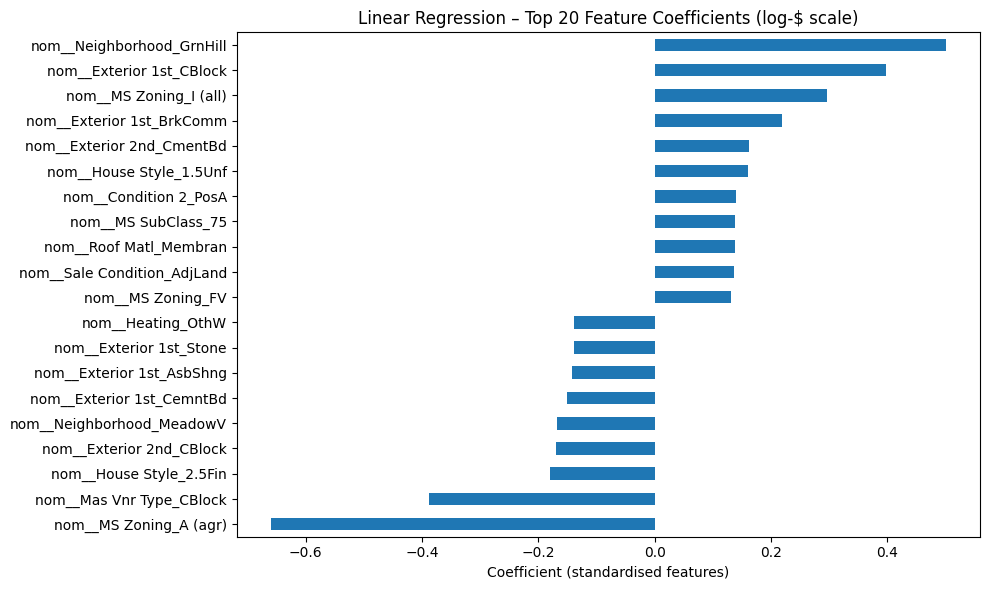

Top 10 most influential features (Linear Regression):


nom__MS Zoning_A (agr)      -0.6606
nom__Neighborhood_GrnHill    0.5010
nom__Exterior 1st_CBlock     0.3969
nom__Mas Vnr Type_CBlock    -0.3888
nom__MS Zoning_I (all)       0.2962
nom__Exterior 1st_BrkComm    0.2189
nom__House Style_2.5Fin     -0.1805
nom__Exterior 2nd_CBlock    -0.1703
nom__Neighborhood_MeadowV   -0.1682
nom__Exterior 2nd_CmentBd    0.1614


In [ ]:
import matplotlib.pyplot as plt

# ── Linear Regression coefficients ───────────────────────────────────────────
lr_model = lr_pipeline.named_steps['model']
coef_series = pd.Series(
    lr_model.coef_,
    index=feature_names_after
).sort_values(key=abs, ascending=False)

top_n = 20
plt.figure(figsize=(10, 6))
coef_series.head(top_n).sort_values().plot(kind='barh')
plt.title(f'Linear Regression – Top {top_n} Feature Coefficients (log-$ scale)')
plt.xlabel('Coefficient (standardised features)')
plt.tight_layout()
plt.show()

print('Top 10 most influential features (Linear Regression):')
print(coef_series.head(10).round(4).to_string())

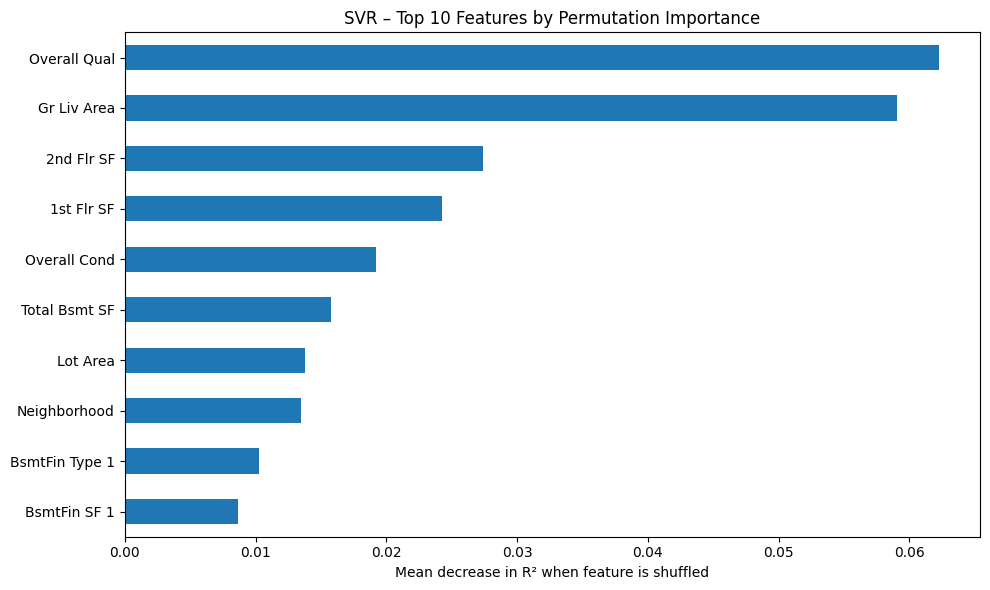

Top 10 most important original features:
Overall Qual      0.0623
Gr Liv Area       0.0591
2nd Flr SF        0.0274
1st Flr SF        0.0243
Overall Cond      0.0192
Total Bsmt SF     0.0158
Lot Area          0.0138
Neighborhood      0.0135
BsmtFin Type 1    0.0103
BsmtFin SF 1      0.0086
dtype: float64


In [ ]:
from sklearn.inspection import permutation_importance

# ── SVR permutation importance (on validation set) ───────────────────────────
# Note: this can take a minute depending on hardware.
perm = permutation_importance(
    svr_best,
    X_val,
    y_val_log,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring='r2'
)

perm_series = pd.Series(
    perm.importances_mean,
    index=X_val.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
perm_series.head(10).sort_values().plot(kind='barh')
plt.title('SVR – Top 10 Features by Permutation Importance')
plt.xlabel('Mean decrease in R² when feature is shuffled')
plt.tight_layout()
plt.show()

print("Top 10 most important original features:")
print(perm_series.head(10).round(4))

### Summary

| | Linear Regression | SVR (tuned) |
|---|---|---|
| **Interpretability** | High (coefficients) | Low (RBF kernel) |
| **Training speed** | Very fast | Slower (scales ≈ O(n²)) |
| **Feature importance** | Coefficients | Permutation importance |
| **Typical generalisation** | Good if data is linear | Better for non-linear data |

Both models keep preprocessing **inside the pipeline**, so they can be
serialised with a single `joblib.dump(pipeline, 'model.pkl')` call and
served without any manual preprocessing at inference time.

If the SVR shows a large train↔val gap even after tuning, consider:
* Reducing `C` (more regularisation).
* Using a Ridge/Lasso regression as a stronger linear baseline.
* Adding more training data or reducing the number of features via selection.